# Educación, competencias cognitivas y empleo en la era de la inteligencia artificial
**Proyecto de Data Analysis · Data Science Bootcamp**

Este notebook resume todos los pasos del análisis exploratorio (EDA). El código auxiliar está en `utils/eda_utils.py`; los borradores de trabajo de cada hipótesis, en `notebooks/`.

## 1. Caso de negocio y pregunta de investigación

> ¿Qué nos permiten comprender la educación formal, la situación migratoria y las competencias cognitivas sobre las perspectivas laborales de las personas, en el contexto del desarrollo de la inteligencia artificial?

El interés del proyecto es práctico: entender qué factores se asocian con tener empleo y cómo se reparten entre el título, el origen migratorio y las competencias reales. El análisis no pretende demostrar causalidad ni medir el efecto de la IA; describe asociaciones dentro de los límites de los datos.

| Hipótesis | Enunciado | Fuente |
|---|---|---|
| **H1** | Más educación formal se asocia con mayor tasa de empleo; la magnitud varía entre países europeos. | Eurostat `lfsa_ergaed` |
| **H2** | Con el mismo nivel educativo, la tasa de empleo de la población migrante es menor que la de la no migrante. | Eurostat `lfsa_erganedm` |
| **H3** | En España, mayores competencias cognitivas (literacy y numeracy) se asocian con mejores resultados laborales, incluso a igual nivel educativo. | OECD PIAAC Ciclo 2 (España) |
| Complemento (no es una 4.ª hipótesis) | ¿Los trabajadores de ocupaciones más expuestas a IA tienen distintas competencias que los de ocupaciones menos expuestas? | PIAAC + índice DAIOE (ISCO-08) |

**Plan de acción previsto.** Si H1-H3 se cumplen, el dato respalda (a) valorar tanto el título como las competencias en los procesos de selección y (b) revisar las barreras que enfrentan los migrantes con estudios superiores. Si no se cumplen, se replantea el enfoque (ver conclusiones).

## 2. Datos y tabla de variables

| Fuente | Variables usadas | Observaciones tras la limpieza |
|---|---|---|
| Eurostat `lfsa_ergaed` | `geo` (país), `TIME_PERIOD` (año), `isced11` (nivel educativo), `OBS_VALUE` (tasa de empleo, %) | 1.137 (36 países, 2015-2025, 25-64 años, ambos sexos) |
| Eurostat `lfsa_erganedm` | las anteriores + `mgstatus` (FBO = nacido en el extranjero, NBO_NAT = nacido en el país de padres nacidos en el país), `sex` | 3.149 (35 geografías, 2021-2025, 15-64 años) |
| OECD PIAAC Ciclo 2, España | `EDLEVEL3` (educación), `PAIDWORK5` (trabajo remunerado en los últimos 5 años), `PVLIT1-10` y `PVNUM1-10` (competencias), `EARNMTHALLPPPC2` (ingreso mensual PPP), `ISCO08_C` (ocupación), `SPFWT0` (peso muestral) | 5.192 personas con nivel educativo y `PAIDWORK5` válidos |
| DAIOE (ISCO-08) | `daioe_allapps` (exposición ocupacional a IA, 2025) | 424 ocupaciones |

Niveles educativos (ISCED 2011): **bajo** = ED0-2 (hasta secundaria obligatoria), **medio** = ED3-4 (bachillerato/FP medio), **alto** = ED5-8 (estudios superiores).

**Decisiones de limpieza**: se eliminan columnas vacías y descriptivas duplicadas; se excluyen los agregados (UE27, zona euro) de los promedios por país; no se imputan los valores ausentes (son datos no publicados por muestra insuficiente) y no se eliminan valores atípicos, porque son países reales cuya diferencia interesa explicar.

In [1]:
import sys
sys.path.insert(0, ".")                      # permite importar utils/ desde src/
from pathlib import Path
from scipy.stats import ttest_ind
from utils.eda_utils import *                # carga de datos, estilo y funciones estadísticas

IMG = Path("../results/figures"); IMG.mkdir(exist_ok=True)   # aquí se guardan los gráficos para la presentación

NAMES = {"BA": "Bosnia y Herz.", "SK": "Eslovaquia", "HR": "Croacia", "PL": "Polonia", "ME": "Montenegro",
         "MK": "Macedonia del N.", "IS": "Islandia", "PT": "Portugal", "CY": "Chipre", "CH": "Suiza",
         "EE": "Estonia", "UK": "Reino Unido", "ES": "España", "BE": "Bélgica"}

## 3. H1 · Educación y empleo en Europa

> **[Autora]** Las celdas siguientes son el análisis de H1 tal como lo hizo la autora en `notebooks/H1_borrador.ipynb` (código y comentarios sin cambios). Solo se ha cambiado la ruta del archivo de datos. Se han omitido tres celdas repetidas.

In [2]:
import pandas as pd

In [3]:
df = pd.read_csv("data/eurostat_employment_education.csv")# первая таблица   # ÚNICO CAMBIO: ruta del archivo (src/data/)

## H1. Educación y empleo en Europa

**Hipótesis:** Las personas con un nivel educativo más alto presentan una mayor tasa de empleo. La magnitud de esta relación varía entre los países europeos.

Esta notebook desarrolla la primera de las tres hipótesis del proyecto *Education, Cognitive Skills and Employment in the Age of Artificial Intelligence*. Los resultados se interpretan como asociaciones descriptivas, no como relaciones causales.

In [4]:
df.head()

,STRUCTURE,STRUCTURE_ID,STRUCTURE_NAME,freq,Time frequency,unit,Unit of measure,sex,Sex,age,...,geo,Geopolitical entity (reporting),TIME_PERIOD,Time,OBS_VALUE,Observation value,OBS_FLAG,Observation status (Flag) V2 structure,CONF_STATUS,Confidentiality status (flag)
0,dataflow,ESTAT:LFSA_ERGAED(1.0),Employment rates by educational attainment level,A,Annual,PC,Percentage,F,Females,Y25-64,...,AT,Austria,2015,NaN,49.1,NaN,NaN,NaN,NaN,NaN
1,dataflow,ESTAT:LFSA_ERGAED(1.0),Employment rates by educational attainment level,A,Annual,PC,Percentage,F,Females,Y25-64,...,AT,Austria,2016,NaN,49.9,NaN,NaN,NaN,NaN,NaN
2,dataflow,ESTAT:LFSA_ERGAED(1.0),Employment rates by educational attainment level,A,Annual,PC,Percentage,F,Females,Y25-64,...,AT,Austria,2017,NaN,49.9,NaN,NaN,NaN,NaN,NaN
3,dataflow,ESTAT:LFSA_ERGAED(1.0),Employment rates by educational attainment level,A,Annual,PC,Percentage,F,Females,Y25-64,...,AT,Austria,2018,NaN,50.6,NaN,NaN,NaN,NaN,NaN
4,dataflow,ESTAT:LFSA_ERGAED(1.0),Employment rates by educational attainment level,A,Annual,PC,Percentage,F,Females,Y25-64,...,AT,Austria,2019,NaN,50.5,NaN,NaN,NaN,NaN,NaN


In [5]:
df["TIME_PERIOD"].unique() #gthbjl 2015 - 2025

array([2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025])

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7218 entries, 0 to 7217
Data columns (total 23 columns):
 #   Column                                                           Non-Null Count  Dtype  
---  ------                                                           --------------  -----  
 0   STRUCTURE                                                        7218 non-null   str    
 1   STRUCTURE_ID                                                     7218 non-null   str    
 2   STRUCTURE_NAME                                                   7218 non-null   str    
 3   freq                                                             7218 non-null   str    
 4   Time frequency                                                   7218 non-null   str    
 5   unit                                                             7218 non-null   str    
 6   Unit of measure                                                  7218 non-null   str    
 7   sex                                                  

In [7]:
df.shape

(7218, 23)

In [8]:
df["TIME_PERIOD"].min(), df["TIME_PERIOD"].max() # период

(np.int64(2015), np.int64(2025))

In [9]:
df["geo"].nunique() # кол-во стран

38

In [10]:
df["isced11"].unique() # категории образования: 
# ED0-2: Начальное и основное образование или ниже.
# ED3_4:Среднее образование и послесреднее, не являющееся высшим. 
# ED5-8: Короткий цикл высшего образования, бакалавриат, магистратура, докторантура..

<StringArray>
['ED0-2', 'ED3_4', 'ED5-8']
Length: 3, dtype: str

In [11]:
# Удаляем столбцы, которые полностью пустые
df = df.dropna(axis=1, how="all")

In [12]:
df.shape
# Проверяем обновлённую структуру

(7218, 19)

In [13]:
df[["sex", "age", "isced11", "OBS_VALUE"]].head() 

,sex,age,isced11,OBS_VALUE
0,F,Y25-64,ED0-2,49.1
1,F,Y25-64,ED0-2,49.9
2,F,Y25-64,ED0-2,49.9
3,F,Y25-64,ED0-2,50.6
4,F,Y25-64,ED0-2,50.5


## H1. Educación y empleo en Europa

### Fuente de datos
- Organismo: Eurostat
- Dataset: lfsa_ergaed
- Archivo: eurostat_employment_education.csv
- Periodo analizado: 2015–2025
- Cobertura geográfica: 38 países/territorios
- Número de registros iniciales: 7.218
- Número de columnas iniciales: 23

### Hipótesis
Las personas con un nivel educativo más alto presentan una mayor tasa de empleo. La magnitud de esta relación varía entre los países europeos.

### Variables principales
| Variable | Descripción |
|---|---|
| geo | País o territorio |
| TIME_PERIOD | Año de observación |
| isced11 | Nivel educativo (clasificación ISCED 2011) |
| sex | Sexo |
| age | Grupo de edad |
| OBS_VALUE | Tasa de empleo (%) |

### Categorías educativas
- ED0-2: Educación baja (ISCED 0–2)
- ED3_4: Educación media (ISCED 3–4)
- ED5-8: Educación alta (ISCED 5–8)

### Análisis previsto
Comparar las tasas de empleo por nivel educativo, país y año.

In [14]:
df["sex"].unique(), df["age"].unique()

(<StringArray>
 ['F', 'M', 'T']
 Length: 3, dtype: str,
 <StringArray>
 ['Y25-64', 'Y25-74']
 Length: 2, dtype: str)

In [15]:
df["geo"].unique()

<StringArray>
[       'AT',        'BA',        'BE',        'BG',        'CH',        'CY',
        'CZ',        'DE',        'DK',      'EA21',        'EE',        'EL',
        'ES', 'EU27_2020',        'FI',        'FR',        'HR',        'HU',
        'IE',        'IS',        'IT',        'LT',        'LU',        'LV',
        'ME',        'MK',        'MT',        'NL',        'NO',        'PL',
        'PT',        'RO',        'RS',        'SE',        'SI',        'SK',
        'TR',        'UK']
Length: 38, dtype: str

In [16]:
df = df[df["age"] == "Y25-64"]# оставляем только возрастную группу 25-64

In [17]:
df["sex"].unique()

<StringArray>
['F', 'M', 'T']
Length: 3, dtype: str

In [18]:
df = df[df["sex"] == "T"] # оставляем только общий показатель по полу

In [19]:
df.shape

(1203, 19)

In [20]:
df["isced11"].unique()

<StringArray>
['ED0-2', 'ED3_4', 'ED5-8']
Length: 3, dtype: str

In [21]:
df["geo"].unique()

<StringArray>
[       'AT',        'BA',        'BE',        'BG',        'CH',        'CY',
        'CZ',        'DE',        'DK',      'EA21',        'EE',        'EL',
        'ES', 'EU27_2020',        'FI',        'FR',        'HR',        'HU',
        'IE',        'IS',        'IT',        'LT',        'LU',        'LV',
        'ME',        'MK',        'MT',        'NL',        'NO',        'PL',
        'PT',        'RO',        'RS',        'SE',        'SI',        'SK',
        'TR',        'UK']
Length: 38, dtype: str

In [22]:
df = df[~df["geo"].isin(["EU27_2020", "EA21"])]

In [23]:
df.shape

(1137, 19)

In [24]:
df["TIME_PERIOD"].unique()

array([2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025])

In [25]:
df.columns

Index(['STRUCTURE', 'STRUCTURE_ID', 'STRUCTURE_NAME', 'freq', 'Time frequency',
       'unit', 'Unit of measure', 'sex', 'Sex', 'age', 'Age class', 'isced11',
       'International Standard Classification of Education (ISCED 2011)',
       'geo', 'Geopolitical entity (reporting)', 'TIME_PERIOD', 'OBS_VALUE',
       'OBS_FLAG', 'Observation status (Flag) V2 structure'],
      dtype='str')

H1 ключевые столбцы:
- geo — страна
- TIME_PERIOD — год
- isced11 — уровень образования
- OBS_VALUE — показатель занятости
- sex — пол
- age — возрастная группа

In [26]:
df["unit"].unique()

<StringArray>
['PC']
Length: 1, dtype: str

In [27]:
df["OBS_VALUE"].describe()

count    1137.000000
mean       72.200352
std        15.066978
min        24.200000
25%        61.100000
50%        75.300000
75%        85.100000
max        93.600000
Name: OBS_VALUE, dtype: float64

In [28]:
df.isnull().sum()

STRUCTURE                                                            0
STRUCTURE_ID                                                         0
STRUCTURE_NAME                                                       0
freq                                                                 0
Time frequency                                                       0
unit                                                                 0
Unit of measure                                                      0
sex                                                                  0
Sex                                                                  0
age                                                                  0
Age class                                                            0
isced11                                                              0
International Standard Classification of Education (ISCED 2011)      0
geo                                                                  0
Geopol

In [29]:
df["OBS_FLAG"].value_counts(dropna=False)

OBS_FLAG
NaN    963
b      144
d       21
bd       9
Name: count, dtype: int64

In [30]:
df.duplicated(subset=["geo", "TIME_PERIOD", "isced11"]).sum() # функция для проверки дубликатов по столбцам geo, TIME_PERIOD и isced11

np.int64(0)

In [31]:
df.groupby("isced11")["OBS_VALUE"].mean().round(2) #первый показатель среднего значения по категориям образования 

isced11
ED0-2    54.85
ED3_4    75.70
ED5-8    86.05
Name: OBS_VALUE, dtype: float64

Первое наблюдение для H1: в нашем наборе данных страны с более высоким уровнем образования демонстрируют более высокий средний уровень занятости.
Разница между низким и высоким уровнем образования составляет 31,20 процентного пункта. Это пока описательный результат, а не доказательство причинно-следственной связи.

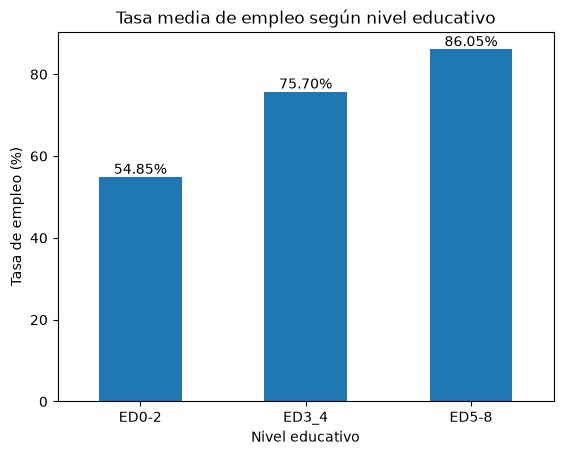

In [32]:
import matplotlib.pyplot as plt

empleo_educacion = df.groupby("isced11")["OBS_VALUE"].mean()

ax = empleo_educacion.plot(kind="bar")

plt.title("Tasa media de empleo según nivel educativo")
plt.xlabel("Nivel educativo")
plt.ylabel("Tasa de empleo (%)")
plt.xticks(rotation=0)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%")

plt.show()

График выше наглядно показывает результат H1: чем выше уровень образования, тем выше средний уровень занятости.

In [33]:
empleo_anual = df.groupby(["TIME_PERIOD", "isced11"])["OBS_VALUE"].mean().unstack() # средний уровень занятости по каждому году отдельно для трёх уровней образования

empleo_anual

isced11,ED0-2,ED3_4,ED5-8
TIME_PERIOD,,,
2015,51.765714,72.562857,83.580000
2016,52.711429,73.314286,84.165714
2017,53.982857,74.588571,84.885714
2018,55.088571,75.617143,85.468571
2019,55.717143,76.131429,85.977143
2020,54.467647,74.805882,85.176471
2021,54.055882,75.364706,86.258824
2022,55.667647,77.082353,87.385294
2023,56.658824,77.438235,87.664706


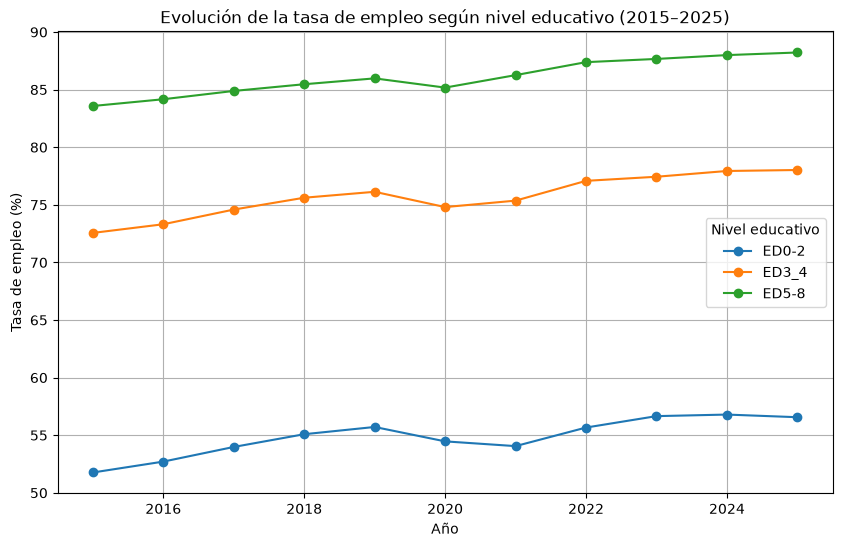

In [34]:
# Рисуем график с линиями для каждого уровня образования по годам

empleo_anual.plot(kind="line", marker="o", figsize=(10, 6))

plt.title("Evolución de la tasa de empleo según nivel educativo (2015–2025)")
plt.xlabel("Año")
plt.ylabel("Tasa de empleo (%)")
plt.legend(title="Nivel educativo")
plt.grid(True)
plt.show()

In [35]:
brecha_educativa = empleo_anual["ED5-8"] - empleo_anual["ED0-2"]

brecha_educativa.round(2)

TIME_PERIOD
2015    31.81
2016    31.45
2017    30.90
2018    30.38
2019    30.26
2020    30.71
2021    32.20
2022    31.72
2023    31.01
2024    31.20
2025    31.66
dtype: float64

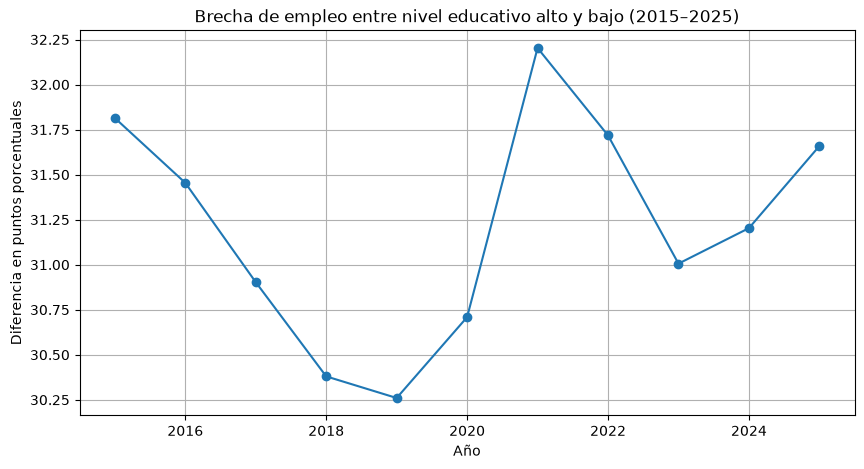

In [36]:
brecha_educativa.plot(kind="line", marker="o", figsize=(10, 5))

plt.title("Brecha de empleo entre nivel educativo alto y bajo (2015–2025)")
plt.xlabel("Año")
plt.ylabel("Diferencia en puntos porcentuales")
plt.grid(True)
plt.show()

«La pandemia de COVID-19 podría haber influido en la evolución de la brecha de empleo entre los distintos niveles educativos, especialmente durante 2020 y 2021. Esta relación requiere un análisis más profundo.»

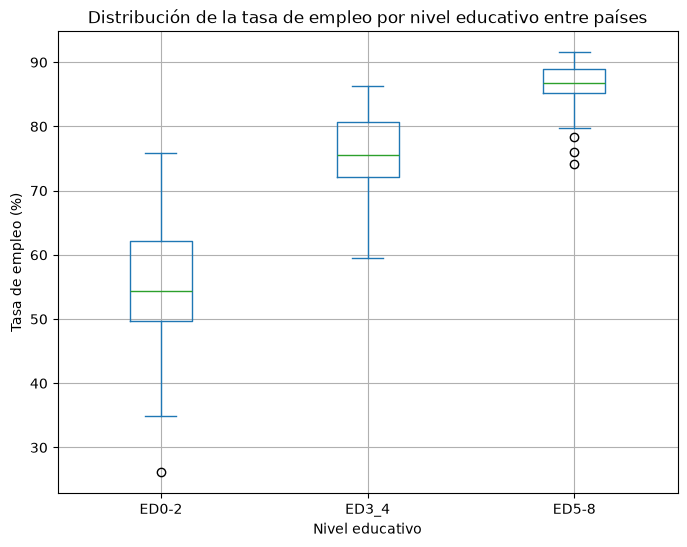

In [37]:
empleo_pais = df.groupby(["geo", "isced11"])["OBS_VALUE"].mean().unstack()

empleo_pais[["ED0-2", "ED3_4", "ED5-8"]].plot(
    kind="box",
    figsize=(8, 6)
)

plt.title("Distribución de la tasa de empleo por nivel educativo entre países")
plt.xlabel("Nivel educativo")
plt.ylabel("Tasa de empleo (%)")
plt.grid(True)
plt.show()

In [38]:
empleo_pais.idxmin()

isced11
ED0-2    BA
ED3_4    ME
ED5-8    TR
dtype: str

In [39]:
empleo_pais.idxmax()

isced11
ED0-2    IS
ED3_4    IS
ED5-8    IS
dtype: str

In [40]:
empleo_pais.loc[["BA", "ME", "TR", "IS"]].round(2) #

isced11,ED0-2,ED3_4,ED5-8
geo,,,
BA,26.10,61.90,81.14
ME,34.97,59.43,78.33
TR,48.14,61.49,74.21
IS,75.83,86.27,91.52


Наблюдение: Исландия показывает самые высокие средние значения занятости во всех образовательных группах. В Боснии и Герцеговине особенно низкая занятость среди людей с низким уровнем образования — 26,10%.

Это подчёркивает, что различия связаны не только с уровнем образования, но и с контекстом конкретной страны.

In [41]:
brecha_pais = empleo_pais["ED5-8"] - empleo_pais["ED0-2"]

brecha_pais.sort_values(ascending=False).round(2)

geo
BA    55.04
SK    50.15
HR    46.18
PL    43.73
ME    43.37
MK    42.56
BG    41.15
LT    40.18
RO    39.59
BE    39.52
SI    37.89
IE    32.85
FR    32.45
FI    32.35
CZ    32.22
AT    31.32
HU    31.01
RS    30.48
IT    29.31
NO    28.30
LV    28.18
SE    27.34
MT    26.37
DE    26.35
DK    26.16
TR    26.07
LU    25.55
NL    24.75
ES    23.80
EL    23.02
UK    22.24
EE    21.99
CH    20.91
CY    19.63
PT    19.37
IS    15.69
dtype: float64

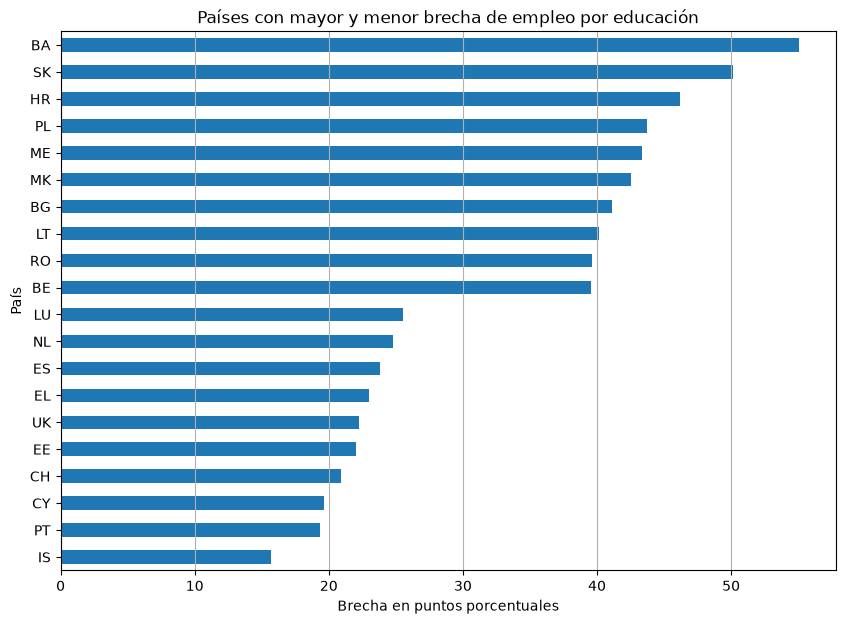

In [42]:
brecha_extremos = pd.concat([
    brecha_pais.sort_values(ascending=False).head(10),
    brecha_pais.sort_values().head(10)
]).sort_values()

brecha_extremos.plot(kind="barh", figsize=(10, 7))

plt.title("Países con mayor y menor brecha de empleo por educación")
plt.xlabel("Brecha en puntos porcentuales")
plt.ylabel("País")
plt.grid(axis="x")
plt.show()

Он наглядно показывает, что разрыв в уровне занятости между людьми с высоким и низким образованием существенно отличается в разных странах.

### Conclusión H1

Los resultados del análisis exploratorio confirman la hipótesis H1. Se observa una relación positiva entre el nivel educativo y la tasa de empleo: cuanto mayor es el nivel educativo, mayor es la tasa media de empleo.

La tasa media de empleo es del 54,85% para las personas con bajo nivel educativo, del 75,70% para el nivel medio y del 86,05% para el nivel alto.

Además, la brecha entre los niveles educativos varía considerablemente entre países, siendo más elevada en Bosnia y Herzegovina (BA) y más reducida en Islandia (IS).

Estos resultados muestran una asociación entre educación y empleo, aunque no permiten establecer una relación causal.

> **[Añadido con ayuda de IA]** Desde aquí, gráficos y cálculos para la presentación. Primero se comprueba que partimos de los mismos datos que usó la autora.

In [43]:
set_style()                          # estilo visual de los gráficos de la presentación (los de arriba usan el estilo por defecto)
h1 = df.copy()                       # el mismo DataFrame de la autora, con el nombre que usan las celdas siguientes
comprobacion = load_education()      # versión equivalente de utils/eda_utils.py
print("¿Mismos datos que el DataFrame de la autora?",
      len(h1) == len(comprobacion) and abs(h1.OBS_VALUE.sum() - comprobacion.OBS_VALUE.sum()) < 1e-9)

¿Mismos datos que el DataFrame de la autora? True


{'ED0-2': 54.85, 'ED3_4': 75.7, 'ED5-8': 86.05} | brecha alto-bajo: 31.21 p.p.


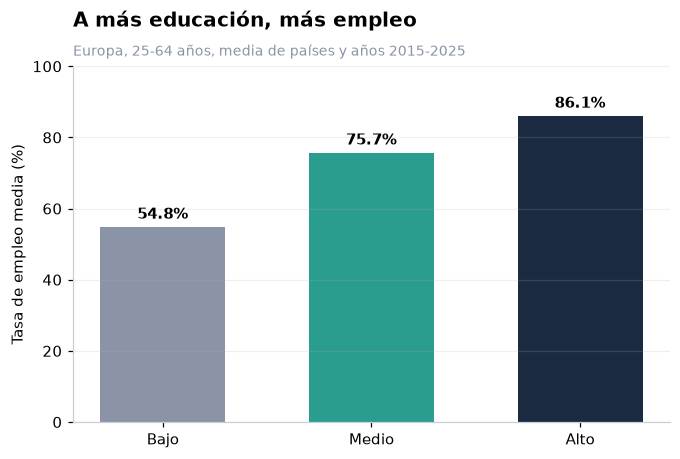

In [44]:
media_nivel = h1.groupby("isced11").OBS_VALUE.mean().reindex(LEVELS)
brecha_total = media_nivel["ED5-8"] - media_nivel["ED0-2"]
print(media_nivel.round(2).to_dict(), "| brecha alto-bajo:", round(brecha_total, 2), "p.p.")

fig, ax = plt.subplots(figsize=(7, 4.2))
bars = ax.bar([LEVEL_NAMES[l] for l in LEVELS], media_nivel.values, color=[GREY, TEAL, NAVY], width=0.6)
ax.bar_label(bars, labels=[f"{round(v + 1e-6, 1):.1f}%" for v in media_nivel.values], padding=3, fontweight="bold")
ax.set_ylim(0, 100); ax.set_ylabel("Tasa de empleo media (%)")
ax.set_title("A más educación, más empleo", pad=26)
ax.text(0, 1.03, "Europa, 25-64 años, media de países y años 2015-2025", transform=ax.transAxes, color=GREY, fontsize=9)
plt.savefig(IMG / "h1_nivel_educativo.png", bbox_inches="tight"); plt.show()

isced11      ED0-2  ED3_4  ED5-8  brecha
TIME_PERIOD                             
2015         51.77  72.56  83.58   31.81
2016         52.71  73.31  84.17   31.45
2017         53.98  74.59  84.89   30.90
2018         55.09  75.62  85.47   30.38
2019         55.72  76.13  85.98   30.26
2020         54.47  74.81  85.18   30.71
2021         54.06  75.36  86.26   32.20
2022         55.67  77.08  87.39   31.72
2023         56.66  77.44  87.66   31.01
2024         56.79  77.94  88.00   31.20
2025         56.56  78.02  88.22   31.66


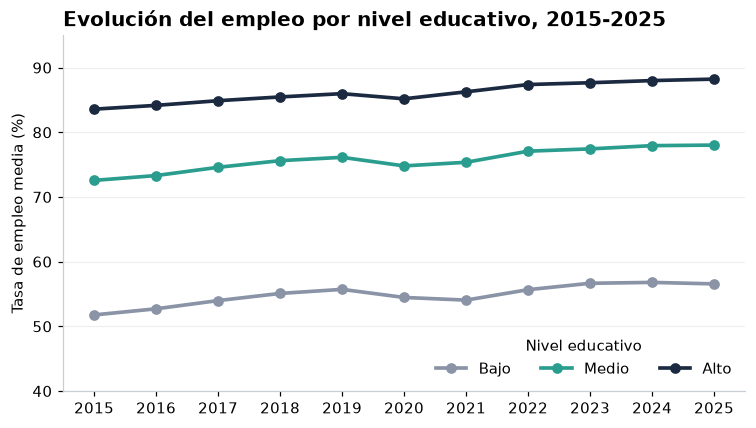

In [45]:
anual = h1.groupby(["TIME_PERIOD", "isced11"]).OBS_VALUE.mean().unstack()[LEVELS]
anual["brecha"] = anual["ED5-8"] - anual["ED0-2"]
print(anual.round(2).to_string())

fig, ax = plt.subplots(figsize=(8, 4.2))
for lvl, col in zip(LEVELS, [GREY, TEAL, NAVY]):
    ax.plot(anual.index, anual[lvl], marker="o", color=col, lw=2.4, label=LEVEL_NAMES[lvl])
ax.set_ylim(40, 95); ax.set_ylabel("Tasa de empleo media (%)"); ax.set_xticks(anual.index)
ax.legend(title="Nivel educativo", frameon=False, ncol=3, loc="lower right")
ax.set_title("Evolución del empleo por nivel educativo, 2015-2025")
plt.savefig(IMG / "h1_evolucion.png", bbox_inches="tight"); plt.show()

Mayor brecha: {'ME': 43.37, 'PL': 43.73, 'HR': 46.18, 'SK': 50.15, 'BA': 55.04}
Menor brecha: {'IS': 15.69, 'PT': 19.37, 'CY': 19.63, 'CH': 20.91, 'EE': 21.99}
España: 23.8 | mediana de países: 29.9 | países: 36


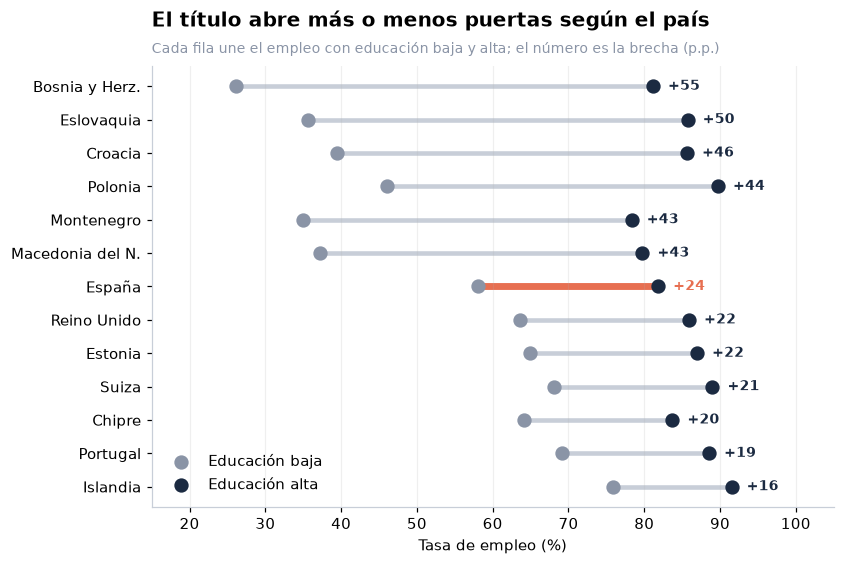

In [46]:
por_pais = h1.groupby(["geo", "isced11"]).OBS_VALUE.mean().unstack()
brecha_pais = (por_pais["ED5-8"] - por_pais["ED0-2"]).sort_values()
print("Mayor brecha:", brecha_pais.tail(5).round(2).to_dict())
print("Menor brecha:", brecha_pais.head(5).round(2).to_dict())
print("España:", round(brecha_pais["ES"], 2), "| mediana de países:", round(brecha_pais.median(), 2),
      "| países:", len(brecha_pais))

sel = pd.concat([brecha_pais.head(6), brecha_pais.tail(6)])
if "ES" not in sel.index:
    sel = pd.concat([sel, brecha_pais[["ES"]]]).sort_values()
fig, ax = plt.subplots(figsize=(8, 5.2))
orden = list(sel.index)                       # de menor a mayor brecha
for i, g in enumerate(orden):
    lo, hi = por_pais.loc[g, "ED0-2"], por_pais.loc[g, "ED5-8"]
    es = g == "ES"
    ax.plot([lo, hi], [i, i], color=ORANGE if es else "#C8CED8", lw=4.5 if es else 3, zorder=1)
    ax.scatter(lo, i, s=70, color=GREY, zorder=2); ax.scatter(hi, i, s=70, color=NAVY, zorder=2)
    ax.text(hi + 2, i, f"+{hi - lo:.0f}", va="center", fontsize=9, fontweight="bold", color=ORANGE if es else NAVY)
ax.set_yticks(range(len(orden)), [NAMES.get(g, g) for g in orden]); ax.set_xlim(15, 105)
ax.set_xlabel("Tasa de empleo (%)"); ax.grid(axis="y", visible=False); ax.grid(axis="x", alpha=0.2)
ax.scatter([], [], s=70, color=GREY, label="Educación baja"); ax.scatter([], [], s=70, color=NAVY, label="Educación alta")
ax.legend(frameon=False, loc="lower left"); ax.set_title("El título abre más o menos puertas según el país", pad=26)
ax.text(0, 1.03, "Cada fila une el empleo con educación baja y alta; el número es la brecha (p.p.)", transform=ax.transAxes, color=GREY, fontsize=9)
plt.savefig(IMG / "h1_brecha_paises.png", bbox_inches="tight"); plt.show()

#### Gráfico para la presentación: «de cada 100 personas»
**Qué hacemos:** convertimos las medias que ya calculamos (55 % y 86 %) en «de cada 100 personas, N trabajan». No es un cálculo nuevo: es otra forma de dibujar el mismo dato, más fácil de entender para el público.

De cada 100 personas con educación baja trabajan 55; con educación alta, 86.


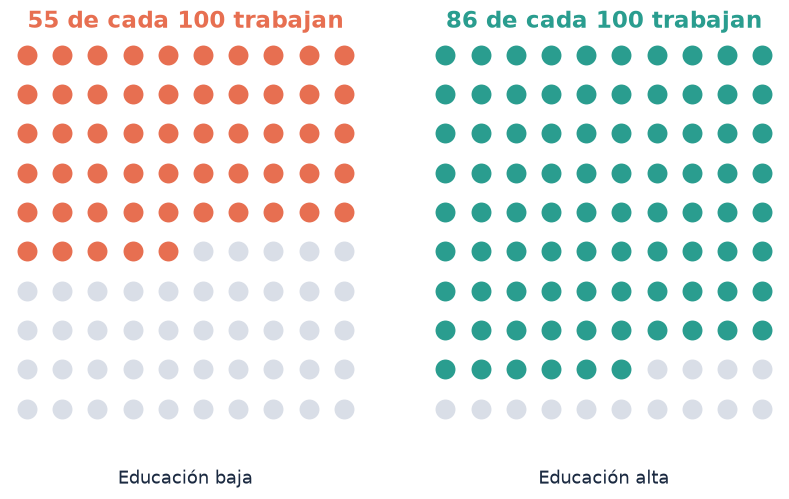

In [47]:
# IDEA: convertir un porcentaje en "de cada 100 personas, N trabajan".
# No es un cálculo nuevo: reutilizamos las medias de empleo que ya calculamos (media_nivel).
n_bajo, n_alto = round(media_nivel["ED0-2"]), round(media_nivel["ED5-8"])
print(f"De cada 100 personas con educación baja trabajan {n_bajo}; con educación alta, {n_alto}.")

fig, axes = plt.subplots(1, 2, figsize=(9, 4.6))
for ax, n, col, titulo in [(axes[0], n_bajo, ORANGE, "Educación baja"), (axes[1], n_alto, TEAL, "Educación alta")]:
    for k in range(100):                                   # 100 puntos en una cuadrícula de 10 x 10
        fila, columna = divmod(k, 10)
        ax.scatter(columna, -fila, s=170, color=col if k < n else "#D9DEE7", linewidths=0)
    ax.set_title(f"{n} de cada 100 trabajan", color=col, fontsize=15, fontweight="bold", loc="center")
    ax.text(4.5, -10.9, titulo, ha="center", color=NAVY, fontsize=12)
    ax.axis("off")
plt.savefig(IMG / "h1_cien_personas.png", bbox_inches="tight"); plt.show()

**Diferencias entre el borrador de la autora y los gráficos añadidos.** Los resultados numéricos son los mismos (54,85 / 75,70 / 86,05 %; brecha de 31,2 p.p.). Lo añadido: (1) los mismos gráficos con un estilo común (colores fijos por nivel educativo, etiquetas más legibles) guardados como imágenes en `results/figures/`; (2) un gráfico «de cada 100 personas» y (3) un resumen de resultados. Nada de lo anterior sustituye el análisis de la autora.

**Resultado H1.** La tasa de empleo crece con el nivel educativo: 54,9 % (bajo), 75,7 % (medio) y 86,1 % (alto), una diferencia de unos 31 puntos porcentuales (p.p.). Esa brecha es estable en 2015-2025 (entre 30 y 32 p.p.): el empleo sube en los tres niveles (aprox. +4,8 p.p. en bajo, +5,5 en medio y +4,6 en alto), pero la distancia entre ellos no se cierra.

Por países, la brecha entre educación alta y baja es positiva en los 36 y varía mucho: de 15,7 p.p. en Islandia a 55,0 en Bosnia y Herzegovina (mediana 29,9; España 23,8). Bosnia, Montenegro y Reino Unido tienen datos incompletos (15-18 de 33 observaciones) y los promedios son simples, sin ponderar por población.

**Conclusión: H1 se confirma.** Mayor nivel educativo se asocia con mayor empleo en todos los países, y la magnitud varía mucho entre ellos. Es una asociación, no una relación causal.

### Veredicto H1: CONFIRMADA

- **Por qué:** se cumple en los 36 países y todos los años, con unos 31 p.p. de diferencia media entre educación alta y baja. La magnitud varía de 16 a 55 p.p.
- **Límite:** son medias por grupo (no personas) y promedios simples de países; no separa el efecto del título de otros factores (edad, sector, situación económica).
- **Para ir más allá:** microdatos individuales con edad y sector (EU-LFS) y medias ponderadas por población.

## 4. H2 · Situación migratoria y empleo

In [48]:
h2 = load_migration()
print("Filas:", len(h2), "| países/agregados:", h2.geo.nunique(), "| años:", sorted(h2.TIME_PERIOD.unique()))
print("Grupos comparados:", h2.mgstatus.unique().tolist(), "(FBO = nacidos en el extranjero, NBO_NAT = nacidos en el país de padres nacidos en el país)")
print("Ausentes en OBS_VALUE:", h2.OBS_VALUE.isna().sum(), "de", len(h2), f"({h2.OBS_VALUE.isna().mean()*100:.1f} %)")
print("Países con más ausentes:", h2[h2.OBS_VALUE.isna()].geo.value_counts().head(5).to_dict())
print("Duplicados:", h2.duplicated(["geo", "sex", "TIME_PERIOD", "isced11", "mgstatus"]).sum())
h2 = h2.dropna(subset=["OBS_VALUE"])          # los ausentes son datos no publicados por baja muestra: no se imputan
gaps = migration_gap(h2)                      # brecha FBO - NBO_NAT por país, año, nivel y sexo
gaps.head()

Filas: 3149 | países/agregados: 35 | años: [np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]
Grupos comparados: ['FBO', 'NBO_NAT'] (FBO = nacidos en el extranjero, NBO_NAT = nacidos en el país de padres nacidos en el país)
Ausentes en OBS_VALUE: 135 de 3149 (4.3 %)
Países con más ausentes: {'RO': 32, 'BG': 28, 'SK': 21, 'LT': 13, 'PL': 13}
Duplicados: 0


mgstatus,geo,sex,TIME_PERIOD,isced11,FBO,NBO_NAT,gap
0,AT,F,2021,ED0-2,42.2,45.1,-2.9
1,AT,F,2021,ED3_4,63.6,71.6,-8.0
2,AT,F,2021,ED5-8,72.0,85.6,-13.6
3,AT,F,2022,ED0-2,42.6,45.1,-2.5
4,AT,F,2022,ED3_4,68.9,74.3,-5.4


UE27 (agregado Eurostat)
 mgstatus    FBO  NBO_NAT  brecha
isced11                         
ED0-2     54.98    44.16   10.82
ED3_4     70.18    73.26   -3.08
ED5-8     77.80    87.82  -10.02 

España
 mgstatus    FBO  NBO_NAT  brecha
isced11                         
ED0-2     56.60    51.38    5.22
ED3_4     65.64    61.20    4.44
ED5-8     74.66    83.14   -8.48


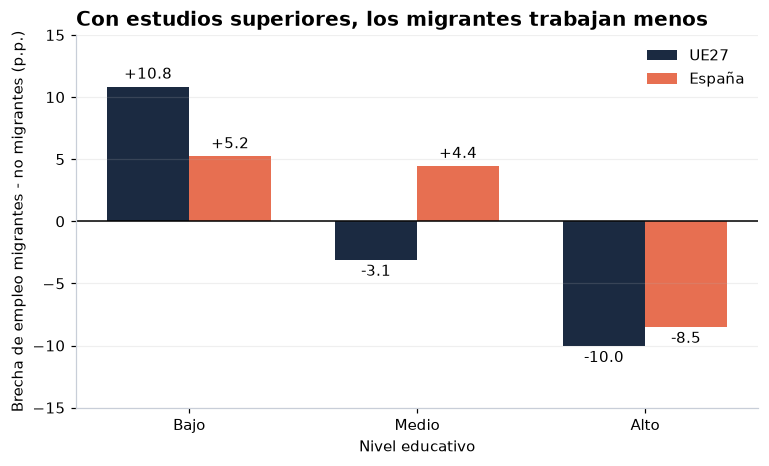

In [49]:
def tabla_brecha(geo):
    t = h2[(h2.geo == geo) & (h2.sex == "T")].groupby(["isced11", "mgstatus"]).OBS_VALUE.mean().unstack().reindex(LEVELS)
    t["brecha"] = t["FBO"] - t["NBO_NAT"]
    return t.round(2)

eu, es = tabla_brecha("EU27_2020"), tabla_brecha("ES")
print("UE27 (agregado Eurostat)\n", eu.to_string(), "\n\nEspaña\n", es.to_string())

x = np.arange(3); w = 0.36
fig, ax = plt.subplots(figsize=(8, 4.4))
b1 = ax.bar(x - w/2, eu["brecha"], w, color=NAVY, label="UE27")
b2 = ax.bar(x + w/2, es["brecha"], w, color=ORANGE, label="España")
ax.bar_label(b1, fmt="%+.1f", padding=3); ax.bar_label(b2, fmt="%+.1f", padding=3)
ax.axhline(0, color="black", lw=1); ax.set_xticks(x, [LEVEL_NAMES[l] for l in LEVELS])
ax.set_xlabel("Nivel educativo"); ax.set_ylabel("Brecha de empleo migrantes - no migrantes (p.p.)")
ax.set_ylim(-15, 15); ax.legend(frameon=False, loc="upper right")
ax.set_title("Con estudios superiores, los migrantes trabajan menos")
plt.savefig(IMG / "h2_brecha_ue_espana.png", bbox_inches="tight"); plt.show()

       países con datos  migrantes con menos empleo  % de países  brecha mediana (p.p.)
Bajo                 31                           4         13.0                   5.28
Medio                34                          25         74.0                  -3.99
Alto                 34                          34        100.0                  -8.39


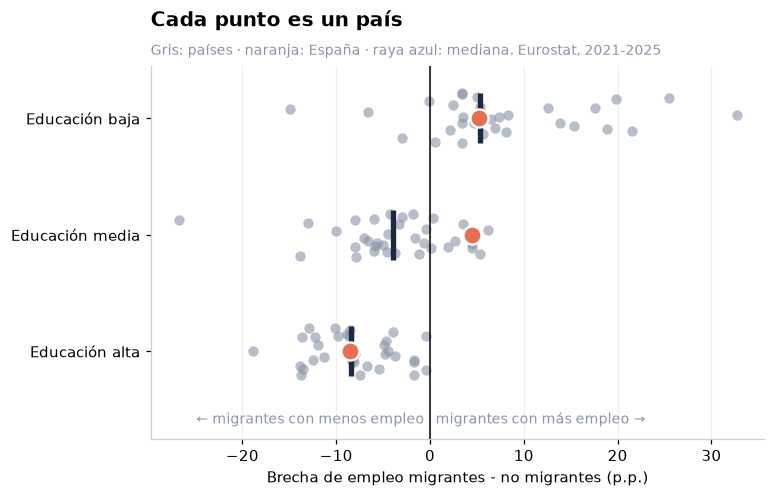

In [50]:
paises = gaps[(gaps.sex == "T") & (gaps.geo != "EU27_2020")]
cg = paises.groupby(["geo", "isced11"]).gap.mean().unstack()[LEVELS]
resumen = pd.DataFrame({
    "países con datos": cg.notna().sum(),
    "migrantes con menos empleo": (cg < 0).sum(),
    "% de países": ((cg < 0).sum() / cg.notna().sum() * 100).round(0),
    "brecha mediana (p.p.)": cg.median().round(2),
})
resumen.index = [LEVEL_NAMES[l] for l in resumen.index]
print(resumen.to_string())

fig, ax = plt.subplots(figsize=(7.2, 4.4)); rng = np.random.default_rng(3)
for i, lvl in enumerate(LEVELS):
    v = cg[lvl].dropna()
    ax.scatter(v, i + rng.uniform(-0.22, 0.22, len(v)), s=46, color=GREY, alpha=0.6, zorder=2, linewidths=0)
    ax.scatter(v.median(), i, s=1100, marker="|", color=NAVY, zorder=4, linewidths=3.5)
    if "ES" in v.index: ax.scatter(v["ES"], i, s=140, color=ORANGE, zorder=6, edgecolor="white", linewidth=1.5)
ax.axvline(0, color="black", lw=1)
ax.set_yticks(range(3), ["Educación baja", "Educación media", "Educación alta"]); ax.set_ylim(2.75, -0.45)
ax.text(-0.6, 2.62, "← migrantes con menos empleo", ha="right", color=GREY, fontsize=9)
ax.text(0.6, 2.62, "migrantes con más empleo →", ha="left", color=GREY, fontsize=9)
ax.set_xlabel("Brecha de empleo migrantes - no migrantes (p.p.)"); ax.grid(axis="y", visible=False); ax.grid(axis="x", alpha=0.2)
ax.set_title("Cada punto es un país", pad=26)
ax.text(0, 1.03, "Gris: países · naranja: España · raya azul: mediana. Eurostat, 2021-2025", transform=ax.transAxes, color=GREY, fontsize=9)
plt.savefig(IMG / "h2_paises_menos_empleo.png", bbox_inches="tight"); plt.show()

#### Gráfico para la presentación: mapa de cuadrados
**Qué hacemos:** dibujamos un cuadrado por país, colocado aproximadamente donde está en Europa. El color y el número son la brecha migrante con educación alta (la tabla `cg` que ya calculamos): naranja significa que los migrantes trabajan menos. No necesitamos ficheros de mapas: cada cuadrado es un rectángulo dibujado con matplotlib en una posición que definimos a mano.

Países en el mapa: 34 | sin posición en el mapa: []


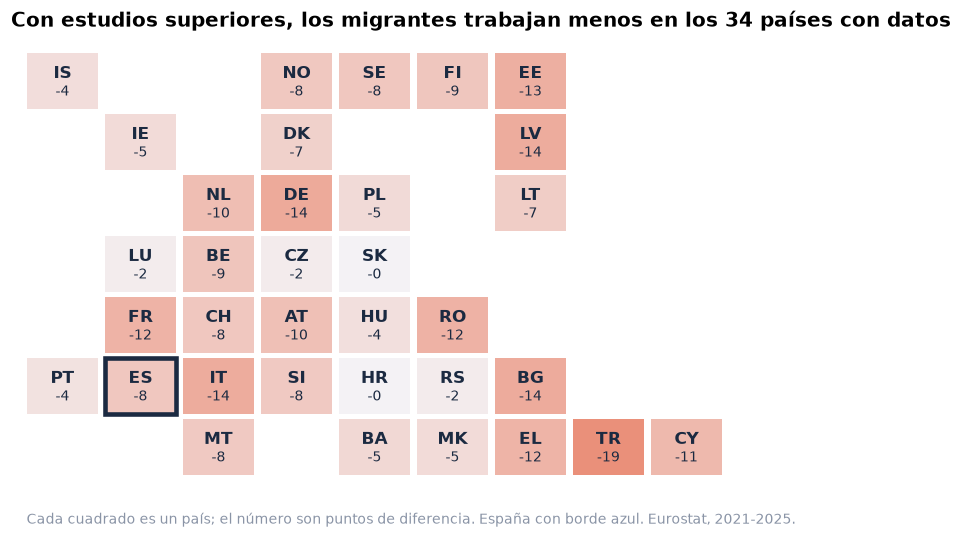

In [51]:
# IDEA: un cuadrado por país, colocado más o menos donde está en Europa. El color es la brecha migrante
# con educación alta (la misma tabla "cg" que ya calculamos arriba): naranja = migrantes con menos empleo.
POS = {"IS": (0, 0), "NO": (0, 3), "SE": (0, 4), "FI": (0, 5), "EE": (0, 6),
       "IE": (1, 1), "DK": (1, 3), "LV": (1, 6),
       "NL": (2, 2), "DE": (2, 3), "PL": (2, 4), "LT": (2, 6),
       "LU": (3, 1), "BE": (3, 2), "CZ": (3, 3), "SK": (3, 4),
       "FR": (4, 1), "CH": (4, 2), "AT": (4, 3), "HU": (4, 4), "RO": (4, 5),
       "PT": (5, 0), "ES": (5, 1), "IT": (5, 2), "SI": (5, 3), "HR": (5, 4), "RS": (5, 5), "BG": (5, 6),
       "MT": (6, 2), "BA": (6, 4), "MK": (6, 5), "EL": (6, 6), "TR": (6, 7), "CY": (6, 8)}
valores = cg["ED5-8"].dropna()
print("Países en el mapa:", len(valores), "| sin posición en el mapa:", sorted(set(valores.index) - set(POS)))

from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list("div", [ORANGE, "#F4F5F8", TEAL])      # naranja (menos) - blanco - verde (más)
fig, ax = plt.subplots(figsize=(8.6, 5.4))
for pais, (fila, col) in POS.items():
    if pais not in valores.index: continue
    v = valores[pais]
    color = cmap((np.clip(v, -25, 25) + 25) / 50)
    ax.add_patch(plt.Rectangle((col, -fila), 0.92, 0.92, color=color, ec=NAVY if pais == "ES" else "none", lw=3 if pais == "ES" else 0))
    ax.text(col + 0.46, -fila + 0.58, pais, ha="center", va="center", fontsize=11, fontweight="bold", color=NAVY)
    ax.text(col + 0.46, -fila + 0.28, f"{v:+.0f}", ha="center", va="center", fontsize=9, color=NAVY)
ax.set_xlim(-0.2, 9.2); ax.set_ylim(-6.3, 1.2); ax.axis("off")
ax.set_title("Con estudios superiores, los migrantes trabajan menos en los 34 países con datos", fontsize=13)
ax.text(0, -6.8, "Cada cuadrado es un país; el número son puntos de diferencia. España con borde azul. Eurostat, 2021-2025.", fontsize=9, color=GREY)
plt.savefig(IMG / "h2_mapa_cuadrados.png", bbox_inches="tight"); plt.show()

España, brecha anual (p.p.)
 isced11      ED0-2  ED3_4  ED5-8
TIME_PERIOD                     
2021           2.9    2.7  -11.2
2022           5.1    3.9   -8.8
2023           6.6    5.2   -7.8
2024           5.8    4.9   -7.9
2025           5.7    5.5   -6.7


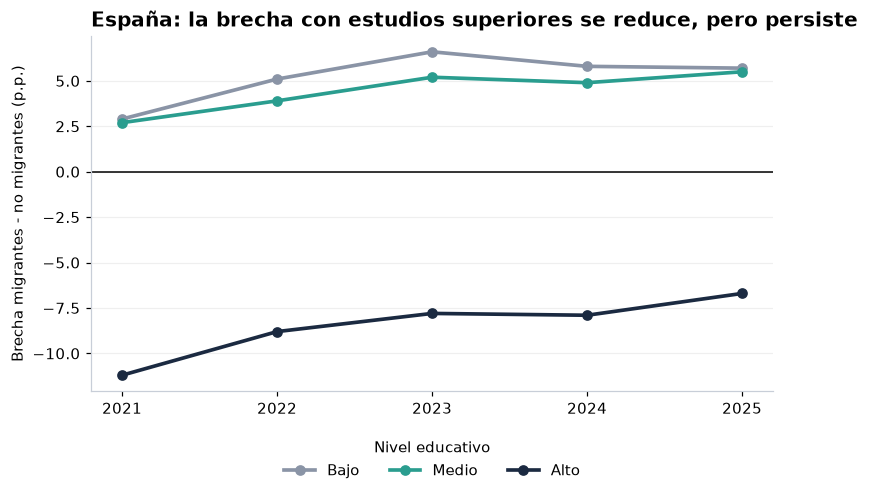


España, educación alta, por sexo
 mgstatus    FBO  NBO_NAT  brecha
sex                             
F         69.86    81.22  -11.36
M         81.20    85.44   -4.24


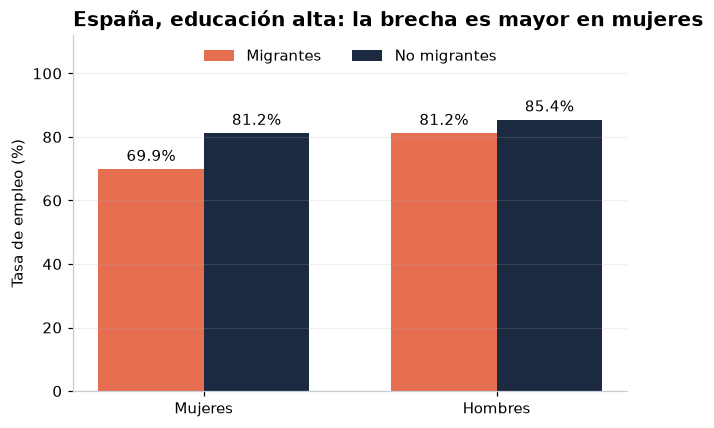

In [52]:
es_anual = gaps[(gaps.geo == "ES") & (gaps.sex == "T")].pivot(index="TIME_PERIOD", columns="isced11", values="gap")[LEVELS]
print("España, brecha anual (p.p.)\n", es_anual.round(1).to_string())

fig, ax = plt.subplots(figsize=(8, 4.2))
for lvl, col in zip(LEVELS, [GREY, TEAL, NAVY]):
    ax.plot(es_anual.index, es_anual[lvl], marker="o", lw=2.4, color=col, label=LEVEL_NAMES[lvl])
ax.axhline(0, color="black", lw=1); ax.set_xticks(es_anual.index)
ax.set_ylabel("Brecha migrantes - no migrantes (p.p.)"); ax.legend(title="Nivel educativo", frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3)
ax.set_title("España: la brecha con estudios superiores se reduce, pero persiste")
plt.savefig(IMG / "h2_espana_evolucion.png", bbox_inches="tight"); plt.show()

alto = h2[(h2.geo == "ES") & (h2.isced11 == "ED5-8")].groupby(["sex", "mgstatus"]).OBS_VALUE.mean().unstack().round(2)
alto["brecha"] = alto["FBO"] - alto["NBO_NAT"]
alto = alto.loc[["F", "M"]]
print("\nEspaña, educación alta, por sexo\n", alto.to_string())

fig, ax = plt.subplots(figsize=(6.5, 4.2)); x = np.arange(2); w = 0.36
b1 = ax.bar(x - w/2, alto["FBO"], w, color=ORANGE, label="Migrantes")
b2 = ax.bar(x + w/2, alto["NBO_NAT"], w, color=NAVY, label="No migrantes")
ax.bar_label(b1, fmt="%.1f%%", padding=3); ax.bar_label(b2, fmt="%.1f%%", padding=3)
ax.set_xticks(x, ["Mujeres", "Hombres"]); ax.set_ylim(0, 112); ax.legend(frameon=False, loc="upper center", ncol=2)
ax.set_ylabel("Tasa de empleo (%)"); ax.set_title("España, educación alta: la brecha es mayor en mujeres")
plt.savefig(IMG / "h2_espana_sexo.png", bbox_inches="tight"); plt.show()

#### Gráfico para la presentación: evolución simplificada
**Qué hacemos:** usamos la tabla `es_anual` de arriba, pero resaltamos solo la línea de educación alta (la que importa para la historia) y dejamos las otras dos en gris.

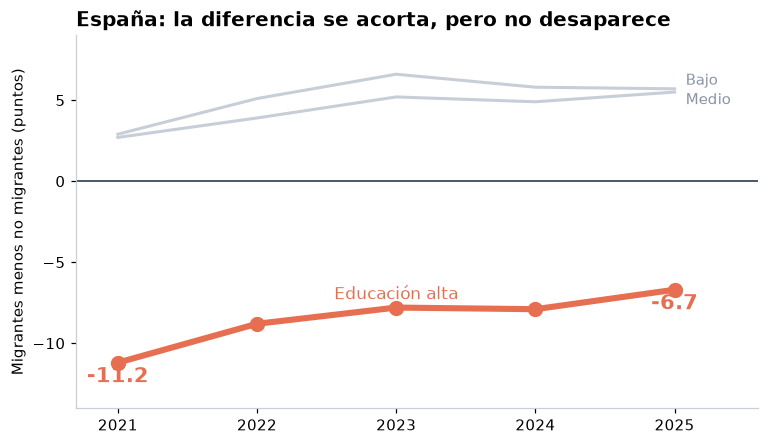

In [53]:
# Versión simplificada del gráfico de evolución: solo destacamos la línea de educación alta.
fig, ax = plt.subplots(figsize=(8, 4.4))
for lvl, nombre in [("ED0-2", "Bajo"), ("ED3_4", "Medio")]:
    ax.plot(es_anual.index, es_anual[lvl], lw=2, color="#C8CED8")
    desfase = 0.5 if lvl == "ED0-2" else -0.5          # separamos las dos etiquetas para que no se pisen
    ax.text(es_anual.index[-1] + 0.08, es_anual[lvl].iloc[-1] + desfase, nombre, color=GREY, va="center", fontsize=10)
ax.plot(es_anual.index, es_anual["ED5-8"], lw=4, color=ORANGE, marker="o", ms=9)
ax.text(2021, es_anual["ED5-8"].iloc[0] - 1.2, f"{es_anual['ED5-8'].iloc[0]:.1f}", ha="center", color=ORANGE, fontsize=14, fontweight="bold")
ax.text(2025, es_anual["ED5-8"].iloc[-1] - 1.2, f"{es_anual['ED5-8'].iloc[-1]:.1f}", ha="center", color=ORANGE, fontsize=14, fontweight="bold")
ax.text(2023, es_anual["ED5-8"].mean() + 1.2, "Educación alta", ha="center", color=ORANGE, fontsize=11)
ax.axhline(0, color=NAVY, lw=1); ax.set_xticks(es_anual.index); ax.set_xlim(2020.7, 2025.6); ax.set_ylim(-14, 9)
ax.set_ylabel("Migrantes menos no migrantes (puntos)"); ax.grid(False)
ax.set_title("España: la diferencia se acorta, pero no desaparece")
plt.savefig(IMG / "h2_espana_simple.png", bbox_inches="tight"); plt.show()

Personas: 5762 | nacidas fuera: 914 (15.9 %)
foreign_born  Nacidos en España  Nacidos fuera
education                                     
Low                        1663            347
Medium                     1107            266
High                       2078            301

% con trabajo remunerado en 5 años
            Nacidos en España  Nacidos fuera  diferencia
education                                              
Low                     71.6           78.8         7.1
Medium                  78.6           87.2         8.7
High                    93.9           91.9        -2.1

Educación baja: edad media 40.4 (fuera) vs 45.6 (España), p = 0.0000
Ocupaciones elementales: 29.0 % vs 20.3 %, p = 0.0064 (n = 224 y 887)
Trabajo remunerado: 78.8 % vs 71.6 %, p = 0.0130


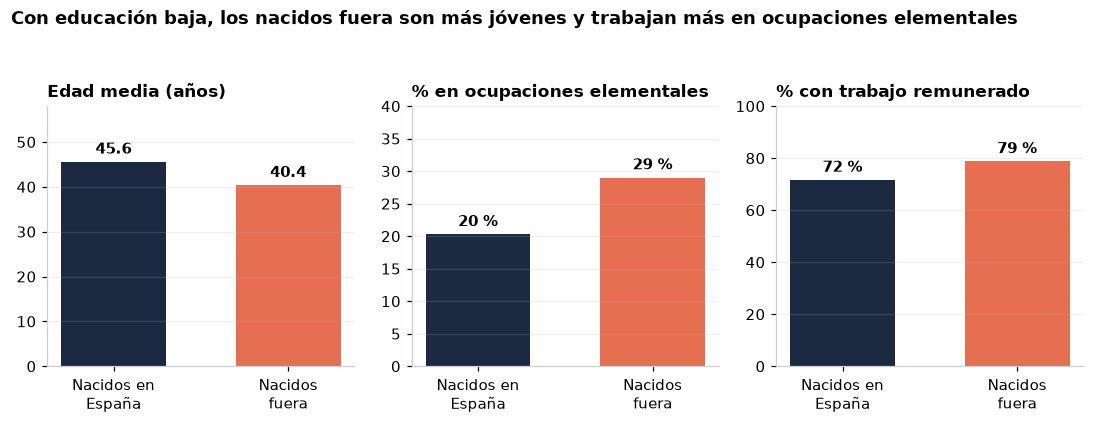

In [54]:
from scipy.stats import chi2_contingency
mig = load_piaac_migration()
print("Personas:", len(mig), "| nacidas fuera:", int(mig.foreign_born.sum()), f"({mig.foreign_born.mean()*100:.1f} %)")
print(pd.crosstab(mig.education, mig.foreign_born).rename(columns={False: "Nacidos en España", True: "Nacidos fuera"}).reindex(["Low", "Medium", "High"]).to_string())

# 1) Trabajo remunerado en los últimos 5 años, por nivel y origen (réplica de H2 con otra fuente)
pw = (mig.dropna(subset=["paid_work"]).groupby(["education", "foreign_born"]).paid_work.mean().unstack() * 100)
pw.columns = ["Nacidos en España", "Nacidos fuera"]; pw = pw.reindex(["Low", "Medium", "High"]); pw["diferencia"] = pw["Nacidos fuera"] - pw["Nacidos en España"]
print("\n% con trabajo remunerado en 5 años\n", pw.round(1).to_string())

low = mig[mig.education == "Low"]
# 2) Edad media (educación baja)
a_f, a_n = low[low.foreign_born].age.dropna(), low[~low.foreign_born].age.dropna()
p_age = ttest_ind(a_f, a_n, equal_var=False).pvalue
# 3) Ocupaciones elementales (ISCO grupo 9) entre quienes tienen ocupación
lo = low.dropna(subset=["occ"]).assign(elem=lambda d: d.occ == 9)
elem = lo.groupby("foreign_born").elem.mean() * 100
p_elem = chi2_contingency(pd.crosstab(lo.foreign_born, lo.elem))[1]
# 4) Trabajo remunerado (educación baja)
lw = low.dropna(subset=["paid_work"]); p_work = chi2_contingency(pd.crosstab(lw.foreign_born, lw.paid_work))[1]
print(f"\nEducación baja: edad media {a_f.mean():.1f} (fuera) vs {a_n.mean():.1f} (España), p = {p_age:.4f}")
print(f"Ocupaciones elementales: {elem[True]:.1f} % vs {elem[False]:.1f} %, p = {p_elem:.4f} (n = {lo.foreign_born.sum()} y {(~lo.foreign_born).sum()})")
print(f"Trabajo remunerado: {pw.loc['Low','Nacidos fuera']:.1f} % vs {pw.loc['Low','Nacidos en España']:.1f} %, p = {p_work:.4f}")

fig, axs = plt.subplots(1, 3, figsize=(10, 3.9))
paneles = [("Edad media (años)", a_n.mean(), a_f.mean(), "%.1f", (0, 58)),
           ("% en ocupaciones elementales", elem[False], elem[True], "%.0f %%", (0, 40)),
           ("% con trabajo remunerado", pw.loc["Low", "Nacidos en España"], pw.loc["Low", "Nacidos fuera"], "%.0f %%", (0, 100))]
for ax, (tit, vn, vf, fmt, lim) in zip(axs, paneles):
    bars = ax.bar(["Nacidos en\nEspaña", "Nacidos\nfuera"], [vn, vf], color=[NAVY, ORANGE], width=0.6)
    ax.bar_label(bars, fmt=fmt, padding=3, fontweight="bold"); ax.set_ylim(*lim); ax.set_title(tit, fontsize=11)
fig.suptitle("Con educación baja, los nacidos fuera son más jóvenes y trabajan más en ocupaciones elementales", x=0.01, ha="left", fontsize=12, fontweight="bold")
plt.tight_layout(rect=(0, 0, 1, 0.93)); plt.savefig(IMG / "h2_pistas_piaac.png", bbox_inches="tight"); plt.show()

**Pistas con PIAAC (complemento exploratorio).** Para entender *por qué* los migrantes con educación baja trabajan más, se usó PIAAC España, donde `BORNLANG` permite distinguir a los nacidos fuera (914 personas, 15,9 %). La lectura de esa variable (códigos 3 y 4 = nacidos fuera) se dedujo de la estructura de los datos, sin consultar el libro de códigos oficial del ciclo 2.

- **Réplica con otra fuente.** Va en la misma dirección que Eurostat: con educación baja trabajan más los nacidos fuera (78,8 % frente a 71,6 %; p = 0,013), también con media (87,2 frente a 78,6), pero no con alta (91,9 frente a 93,9).
- **Edad.** Con educación baja, los nacidos fuera son 5 años más jóvenes (40,4 frente a 45,6; p < 0,001). Una explicación posible es que las personas sin título nacidas en España pertenecen a generaciones mayores, con más personas fuera del mercado laboral.
- **Tipo de trabajo.** Con educación baja, el 29,0 % de los nacidos fuera trabaja en ocupaciones elementales (ISCO grupo 9) frente al 20,3 % de los nacidos en España (p = 0,006).

Son pistas, no pruebas: muestras pequeñas (347 nacidos fuera con educación baja), sin pesos muestrales ni controles, y `PAIDWORK5` no es la tasa de empleo. Siguen sin explicar la causa (necesidad de trabajar, sectores, selección migratoria).

**Resultado H2.** El resultado depende del nivel educativo. En la UE27 los migrantes con educación baja tienen **más** empleo (+10,8 p.p.), con educación media algo menos (−3,1) y con educación alta bastante menos (−10,0). España sigue el patrón solo con educación alta (−8,5 p.p.); con educación baja y media los migrantes tienen más empleo (+5,2 y +4,4).

Con educación alta, los migrantes tienen menos empleo en los **34 de 34 países** con datos; con educación media en 25 de 34 (74 %) y con baja solo en 4 de 31 (13 %). En España la brecha con educación alta se redujo de −11,2 p.p. (2021) a −6,7 (2025), pero persiste, y es mayor en mujeres (−11,4 p.p.) que en hombres (−4,2).

**Conclusión: H2 se confirma parcialmente.** Se cumple con educación media y alta, y no con educación baja. Los datos no explican *por qué* (reconocimiento de títulos, idioma, redes, sectores): una posible explicación son diferencias sectoriales y ocupacionales, a investigar. Los datos agregados de Eurostat no permiten hablar de casos individuales, y la UE27 incluye a España.

### Veredicto H2: CONFIRMADA PARCIALMENTE

- **Por qué solo parcialmente:** se cumple con educación media (25 de 34 países) y alta (34 de 34), pero con educación baja ocurre lo contrario (migrantes +10,8 p.p. en la UE27).
- **Por qué no podemos explicarlo:** Eurostat da medias por grupo, sin edad, sector, años de residencia ni país donde se obtuvo el título. «Mismo nivel educativo» en el papel no implica el mismo reconocimiento del título. Las pistas de PIAAC (más jóvenes, más ocupaciones elementales) son exploratorias.
- **Para ir más allá:** microdatos EU-LFS con edad, sector, años desde la llegada y país de estudio; tasa de sobrecualificación (trabajar por debajo de la propia formación); estudios cualitativos sobre reconocimiento de títulos.

## 5. H3 · Competencias cognitivas y resultados laborales en España

In [55]:
h3 = load_piaac()
print("Personas analizadas (con nivel educativo y respuesta válida en PAIDWORK5):", len(h3))
print(h3.education.value_counts().reindex(["Low", "Medium", "High"]).to_dict())
tabla = (pd.crosstab(h3.education, h3.paid_work, normalize="index") * 100).reindex(["Low", "Medium", "High"]).round(2)
tabla.columns = ["Sin trabajo remunerado en 5 años (%)", "Con trabajo remunerado en 5 años (%)"]
tabla

Personas analizadas (con nivel educativo y respuesta válida en PAIDWORK5): 5192
{'Low': 1793, 'Medium': 1203, 'High': 2196}


,Sin trabajo remunerado en 5 años (%),Con trabajo remunerado en 5 años (%)
education,,
Low,27.11,72.89
Medium,19.70,80.30
High,6.28,93.72


In [56]:
habil = h3.groupby(["education", "paid_work"])[["literacy", "numeracy"]].mean().round(2)
print(habil.to_string())
print("\nMedia de competencias por nivel educativo:", h3.groupby("education").cognitive.mean().round(1).to_dict())

                     literacy  numeracy
education paid_work                    
High      0            261.58    265.37
          1            273.83    277.90
Low       0            219.68    219.48
          1            229.14    229.79
Medium    0            250.01    252.52
          1            251.05    256.00

Media de competencias por nivel educativo: {'High': 275.1, 'Low': 226.8, 'Medium': 253.1}


cog_quartile    Q1    Q2    Q3    Q4
education                           
Low           68.7  76.6  76.3  77.1
Medium        77.0  81.5  83.2  78.5
High          89.5  92.4  93.3  95.5

 Nivel  chi2  p-valor  V de Cramér
   Low 14.10   0.0028        0.089
Medium  4.45   0.2168        0.061
  High 12.03   0.0073        0.074


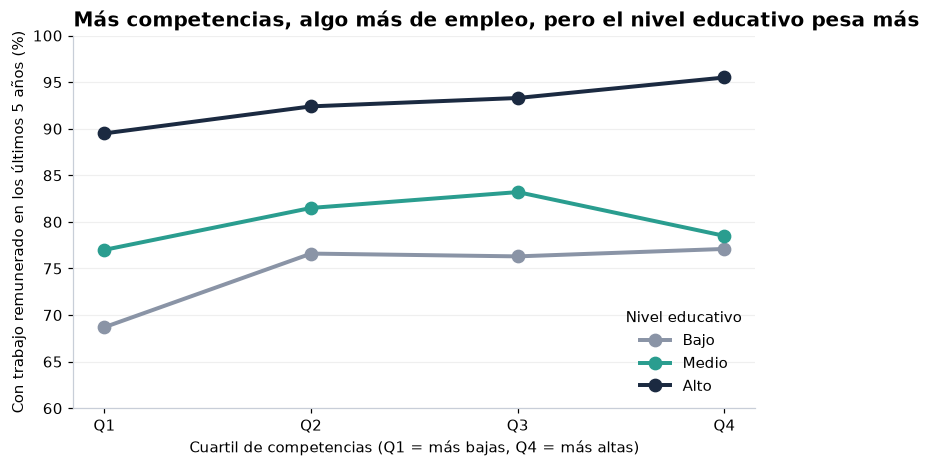

In [57]:
h3["cog_quartile"] = pd.qcut(h3.cognitive.rank(method="first"), 4, labels=["Q1", "Q2", "Q3", "Q4"])
emp_q = (pd.crosstab([h3.education, h3.cog_quartile], h3.paid_work, normalize="index") * 100)[1].unstack().round(1)
emp_q = emp_q.reindex(["Low", "Medium", "High"])
print(emp_q.to_string()); print()
print(chi2_by_level(h3).to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 4.4))
for lvl, col, lab in [("Low", GREY, "Bajo"), ("Medium", TEAL, "Medio"), ("High", NAVY, "Alto")]:
    ax.plot(emp_q.columns, emp_q.loc[lvl], marker="o", ms=8, lw=2.6, color=col, label=lab)
ax.set_ylim(60, 100); ax.set_xlabel("Cuartil de competencias (Q1 = más bajas, Q4 = más altas)")
ax.set_ylabel("Con trabajo remunerado en los últimos 5 años (%)")
ax.legend(title="Nivel educativo", frameon=False, loc="lower right")
ax.set_title("Más competencias, algo más de empleo, pero el nivel educativo pesa más")
plt.savefig(IMG / "h3_cuartiles.png", bbox_inches="tight"); plt.show()

{'Educación: de baja a alta': np.float64(20.8), 'Competencias, Q1 a Q4 (nivel bajo)': np.float64(8.4), 'Competencias, Q1 a Q4 (nivel medio)': np.float64(1.5), 'Competencias, Q1 a Q4 (nivel alto)': np.float64(6.0)}


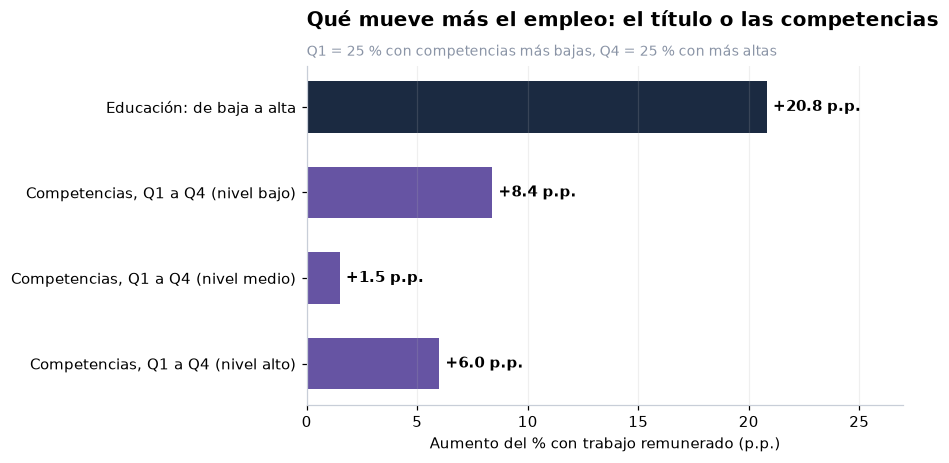

In [58]:
emp_edu = h3.groupby("education").paid_work.mean() * 100
barras = [("Educación: de baja a alta", emp_edu["High"] - emp_edu["Low"], NAVY)]
for lvl, nm in [("Low", "bajo"), ("Medium", "medio"), ("High", "alto")]:
    barras.append((f"Competencias, Q1 a Q4 (nivel {nm})", emp_q.loc[lvl, "Q4"] - emp_q.loc[lvl, "Q1"], PURPLE))
print({b[0]: round(b[1], 1) for b in barras})
fig, ax = plt.subplots(figsize=(7.0, 4.0))
bars = ax.barh([b[0] for b in barras][::-1], [b[1] for b in barras][::-1], color=[b[2] for b in barras][::-1], height=0.6)
ax.bar_label(bars, fmt="+%.1f p.p.", padding=4, fontweight="bold"); ax.set_xlim(0, 27)
ax.set_xlabel("Aumento del % con trabajo remunerado (p.p.)")
ax.grid(axis="y", visible=False); ax.grid(axis="x", alpha=0.2)
ax.set_title("Qué mueve más el empleo: el título o las competencias", pad=26)
ax.text(0, 1.03, "Q1 = 25 % con competencias más bajas, Q4 = 25 % con más altas", transform=ax.transAxes, color=GREY, fontsize=9)
plt.savefig(IMG / "h3_educacion_vs_competencias.png", bbox_inches="tight"); plt.show()

#### Diploma sin competencias o competencias sin diploma
**Pregunta:** ¿quién trabaja más: quien tiene título pero competencias bajas, o quien tiene competencias altas pero no título?

**Pasos:** (1) calculamos la mediana de competencias de todas las personas (el valor que deja a la mitad por debajo y a la mitad por encima); (2) etiquetamos a cada persona como «competencias bajas» o «altas»; (3) nos quedamos con educación baja y alta; (4) en cada uno de los cuatro grupos, calculamos el porcentaje con trabajo remunerado en los últimos cinco años.

**Cómo leerlo:** es una comparación descriptiva (cuatro porcentajes), no un modelo. Sirve para ilustrar que el título pesa más, no para demostrar causas.

Mediana de competencias: 255.3
                        personas  pct_trabajo
education competencias                       
High      Altas             1570         94.6
          Bajas              626         91.5
Low       Altas              448         76.6
          Bajas             1345         71.7


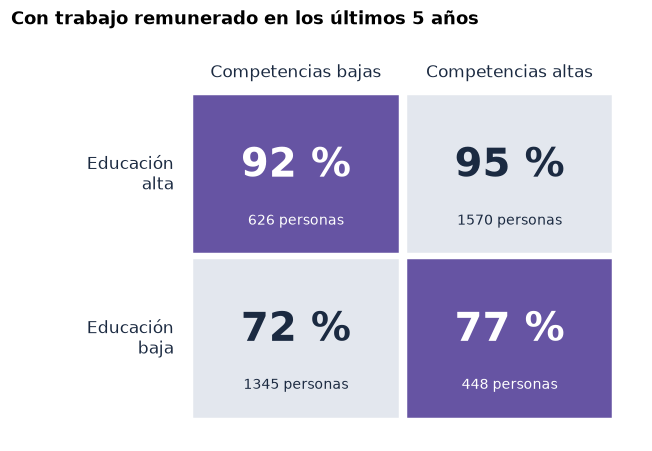

In [59]:
# PREGUNTA: ¿quién trabaja más, quien tiene título pero pocas competencias, o quien tiene competencias pero no título?
# PASOS: (1) dividimos a todas las personas en dos grupos según su competencia (por debajo / por encima de la mediana);
#        (2) nos quedamos con educación baja y alta; (3) en cada uno de los 4 grupos, calculamos el % con trabajo remunerado.
mediana = h3.cognitive.median()
h3["competencias"] = np.where(h3.cognitive >= mediana, "Altas", "Bajas")
cuatro = h3[h3.education.isin(["Low", "High"])].groupby(["education", "competencias"]).agg(
    personas=("paid_work", "size"), pct_trabajo=("paid_work", lambda s: s.mean() * 100)).round(1)
print("Mediana de competencias:", round(mediana, 1)); print(cuatro.to_string())

fig, ax = plt.subplots(figsize=(7.4, 4.8))
celdas = [("High", "Bajas", 0, 0), ("High", "Altas", 1, 0), ("Low", "Bajas", 0, 1), ("Low", "Altas", 1, 1)]
for edu, comp, c, f in celdas:
    v, n = cuatro.loc[(edu, comp), "pct_trabajo"], int(cuatro.loc[(edu, comp), "personas"])
    ax.add_patch(plt.Rectangle((c * 1.05, -f * 1.05), 1, 1, color=PURPLE if (edu, comp) in [("Low", "Altas"), ("High", "Bajas")] else "#E3E7EE"))
    txt_col = "white" if (edu, comp) in [("Low", "Altas"), ("High", "Bajas")] else NAVY
    ax.text(c * 1.05 + 0.5, -f * 1.05 + 0.55, f"{v:.0f} %", ha="center", va="center", fontsize=26, fontweight="bold", color=txt_col)
    ax.text(c * 1.05 + 0.5, -f * 1.05 + 0.2, f"{n} personas", ha="center", va="center", fontsize=9, color=txt_col)
ax.text(0.5, 1.12, "Competencias bajas", ha="center", fontsize=11, color=NAVY); ax.text(1.55, 1.12, "Competencias altas", ha="center", fontsize=11, color=NAVY)
ax.text(-0.1, 0.5, "Educación\nalta", ha="right", va="center", fontsize=11, color=NAVY); ax.text(-0.1, -0.55, "Educación\nbaja", ha="right", va="center", fontsize=11, color=NAVY)
ax.set_xlim(-0.9, 2.2); ax.set_ylim(-1.2, 1.4); ax.axis("off")
ax.set_title("Con trabajo remunerado en los últimos 5 años", fontsize=12)
plt.savefig(IMG / "h3_titulo_vs_competencias.png", bbox_inches="tight"); plt.show()

                             OR  IC95 inf  IC95 sup  OR con pesos muestrales
Competencias (+10 puntos)  1.05      1.03      1.07                     1.02
Educación media vs baja    1.33      1.13      1.57                     1.35
Educación alta vs baja     4.37      3.51      5.33                     5.13
Pseudo-R² (McFadden): 0.08


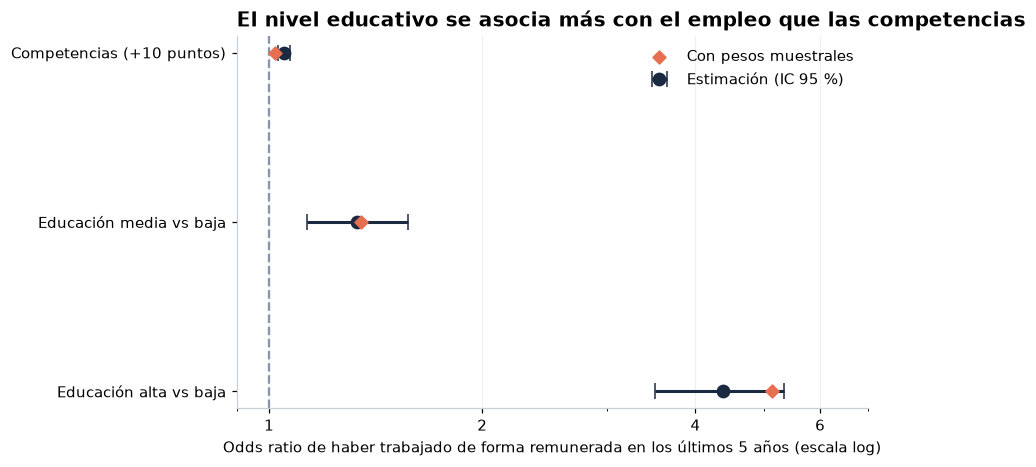

In [60]:
orr, r2 = logit_odds_ratios(h3)
lo, hi = bootstrap_or(h3, n=300)
orw, r2w = logit_odds_ratios(h3.dropna(subset=["SPFWT0"]), weights=h3.dropna(subset=["SPFWT0"]).SPFWT0.values)
res = pd.DataFrame({"OR": orr, "IC95 inf": lo, "IC95 sup": hi, "OR con pesos muestrales": orw},
                   index=["Competencias (+10 puntos)", "Educación media vs baja", "Educación alta vs baja"]).round(2)
print(res.to_string()); print("Pseudo-R² (McFadden):", round(r2, 3))

labels = res.index[::-1]; y = np.arange(3)
fig, ax = plt.subplots(figsize=(7.4, 4.4))
ax.errorbar(res["OR"][::-1], y, xerr=[(res["OR"] - res["IC95 inf"])[::-1], (res["IC95 sup"] - res["OR"])[::-1]],
            fmt="o", color=NAVY, capsize=5, ms=8, lw=2, label="Estimación (IC 95 %)")
ax.scatter(res["OR con pesos muestrales"][::-1], y, marker="D", color=ORANGE, zorder=3, label="Con pesos muestrales")
ax.axvline(1, color=GREY, ls="--"); ax.set_yticks(y, labels); ax.set_xscale("log"); ax.set_xticks([1, 2, 4, 6], ["1", "2", "4", "6"]); ax.xaxis.set_minor_formatter(plt.NullFormatter()); ax.set_xlim(0.9, 7)
ax.set_xlabel("Odds ratio de haber trabajado de forma remunerada en los últimos 5 años (escala log)")
ax.grid(axis="y", visible=False); ax.grid(axis="x", alpha=0.2); ax.legend(frameon=False, loc="upper right")
ax.set_title("El nivel educativo se asocia más con el empleo que las competencias")
plt.savefig(IMG / "h3_odds_ratios.png", bbox_inches="tight"); plt.show()

Asalariados con ingreso mensual (PPP) válido: 3317 | R² = 0.103
{'Competencias (+10 puntos)': '+1.9 %', 'Educación media vs baja': '+10.1 %', 'Educación alta vs baja': '+55.3 %'} | t-valores: [5.5, 2.6, 13.1]
Ingreso mensual mediano por nivel (USD PPP): {'High': 3743.0, 'Low': 2246.0, 'Medium': 2592.0}


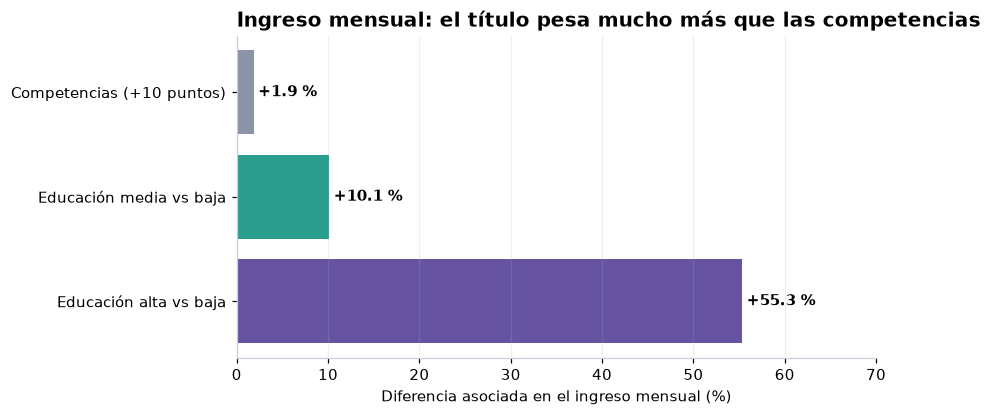

In [61]:
# EARNMTHALLPPPC2 = ingreso mensual en USD ajustados por paridad de poder adquisitivo (= EARNMTHALLC2 x 1,7277, factor constante)
n, b, t, r2i = income_model(h3)
ef = {"Competencias (+10 puntos)": (np.exp(b[1]) - 1) * 100,
      "Educación media vs baja": (np.exp(b[2]) - 1) * 100,
      "Educación alta vs baja": (np.exp(b[3]) - 1) * 100}
print(f"Asalariados con ingreso mensual (PPP) válido: {n} | R² = {r2i:.3f}")
print({k: f"{v:+.1f} %" for k, v in ef.items()}, "| t-valores:", t[1:].round(1).tolist())
print("Ingreso mensual mediano por nivel (USD PPP):", h3[h3.EARNMTHALLPPPC2 > 0].groupby("education").EARNMTHALLPPPC2.median().round(0).to_dict())

fig, ax = plt.subplots(figsize=(7.5, 3.8))
bars = ax.barh(list(ef.keys())[::-1], list(ef.values())[::-1], color=[PURPLE, TEAL, GREY])
ax.bar_label(bars, fmt="%+.1f %%", padding=3, fontweight="bold")
ax.set_xlabel("Diferencia asociada en el ingreso mensual (%)"); ax.set_xlim(0, 70)
ax.grid(axis="y", visible=False); ax.grid(axis="x", alpha=0.2)
ax.set_title("Ingreso mensual: el título pesa mucho más que las competencias")
plt.savefig(IMG / "h3_ingreso.png", bbox_inches="tight"); plt.show()

**Resultado H3.** Las competencias son más altas entre quienes tienen más educación (media 227 en nivel bajo, 253 en medio, 275 en alto) y, dentro de cada nivel, entre quienes han tenido trabajo remunerado. La asociación existe, pero es **débil**:

- Por cuartiles de competencias, el empleo sube de forma moderada; la asociación es significativa en nivel bajo (p = 0,003) y alto (p = 0,007) y no lo es en nivel medio (p = 0,22). La intensidad es baja (V de Cramér entre 0,06 y 0,09).
- En el modelo logístico, +10 puntos de competencias se asocian con un 5 % más de odds de haber trabajado (OR 1,05; IC 95 % 1,03-1,07), mientras que tener educación alta frente a baja multiplica las odds por 4,4. Con los **pesos muestrales** de PIAAC el efecto de las competencias casi desaparece (OR 1,02) y el de la educación alta aumenta (5,1): el resultado sobre competencias es frágil.
- Con el **ingreso mensual** como segundo resultado (3.317 personas con ingreso declarado; USD ajustados por PPP), +10 puntos de competencias se asocian con un +1,9 % de ingreso, frente a +55 % de la educación alta respecto a la baja (+10 % la media).

**Conclusión: H3 se confirma parcialmente.** Las competencias se asocian de forma positiva, pero modesta, con mejores resultados laborales a igual nivel educativo; en estos datos el nivel educativo se asocia mucho más con el empleo y el ingreso. `PAIDWORK5` mide haber trabajado en los últimos 5 años, no la situación actual; el ingreso solo existe para quienes trabajan y lo declaran, y los valores extremos pueden estar truncados en el archivo público; las medias de *plausible values* son exploratorias; y los datos son observacionales.

### Análisis complementario · Competencias y exposición ocupacional a IA

Registros con ocupación válida: 3915 | emparejados con DAIOE: 3864 (98.7 %)
Personas por grupo: {'Baja exposición': 2020, 'Alta exposición': 1844}
 Nivel  n alta  n baja  media alta  media baja  diferencia  p-valor (Welch)
   Low     294     814     236.928     229.194       7.734            0.004
Medium     345     511     257.340     249.273       8.067            0.002
  High    1205     695     280.239     269.643      10.596            0.000


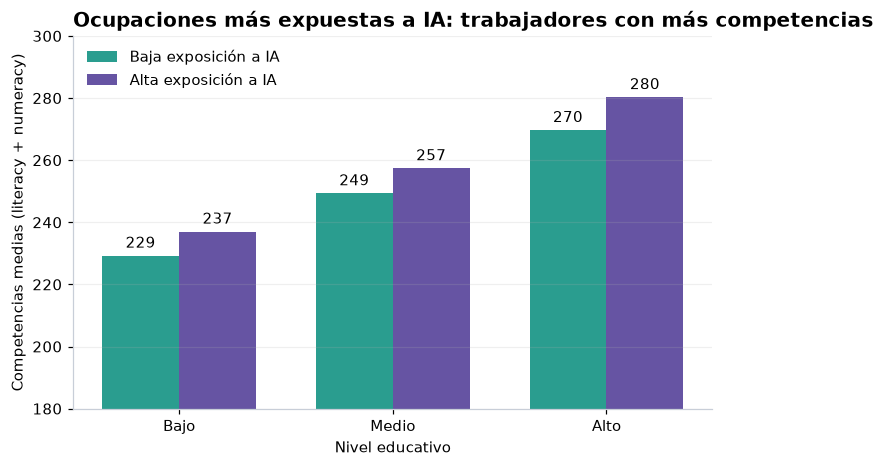

In [62]:
daioe = load_daioe(2025)
ai = h3.copy()
ai["isco"] = pd.to_numeric(ai.ISCO08_C, errors="coerce")
ai = ai[ai.isco.notna() & (ai.isco != 9996)]                       # 9996 = sin código válido
ai = ai.merge(daioe[["isco", "daioe_allapps"]], on="isco", how="left")
print(f"Registros con ocupación válida: {len(ai)} | emparejados con DAIOE: {ai.daioe_allapps.notna().sum()} "
      f"({ai.daioe_allapps.notna().mean()*100:.1f} %)")

umbral = daioe.daioe_allapps.median()                              # mediana del índice entre las ocupaciones
ai = ai[ai.daioe_allapps.notna()].copy()
ai["ai_group"] = np.where(ai.daioe_allapps >= umbral, "Alta exposición", "Baja exposición")
print("Personas por grupo:", ai.ai_group.value_counts().to_dict())

filas = []
for lvl in ["Low", "Medium", "High"]:
    a = ai[(ai.education == lvl) & (ai.ai_group == "Alta exposición")].cognitive
    b_ = ai[(ai.education == lvl) & (ai.ai_group == "Baja exposición")].cognitive
    filas.append({"Nivel": lvl, "n alta": len(a), "n baja": len(b_), "media alta": a.mean(), "media baja": b_.mean(),
                  "diferencia": a.mean() - b_.mean(), "p-valor (Welch)": ttest_ind(a, b_, equal_var=False).pvalue})
tab_ai = pd.DataFrame(filas).round(3); print(tab_ai.to_string(index=False))

graf = ai.groupby(["education", "ai_group"]).cognitive.mean().unstack().reindex(["Low", "Medium", "High"])
fig, ax = plt.subplots(figsize=(7.5, 4.4)); x = np.arange(3); w = 0.36
b1 = ax.bar(x - w/2, graf["Baja exposición"], w, color=TEAL, label="Baja exposición a IA")
b2 = ax.bar(x + w/2, graf["Alta exposición"], w, color=PURPLE, label="Alta exposición a IA")
ax.bar_label(b1, fmt="%.0f", padding=3); ax.bar_label(b2, fmt="%.0f", padding=3)
ax.set_xticks(x, ["Bajo", "Medio", "Alto"]); ax.set_xlabel("Nivel educativo"); ax.set_ylim(180, 300)
ax.set_ylabel("Competencias medias (literacy + numeracy)"); ax.legend(frameon=False, loc="upper left")
ax.set_title("Ocupaciones más expuestas a IA: trabajadores con más competencias")
plt.savefig(IMG / "h3_exposicion_ia.png", bbox_inches="tight"); plt.show()

#### Porcentajes de la presentación: ¿quién trabaja en ocupaciones muy expuestas a la IA?
**Qué hacemos:** con la tabla `ai` de arriba (ocupaciones enlazadas con DAIOE), calculamos qué porcentaje de cada grupo trabaja en ocupaciones con exposición por encima de la mediana de las ocupaciones. Son los números de las diapositivas «los mismos cuatro grupos», «63 / 40 / 27» y «36 frente a 58». > **[Añadido con ayuda de IA]** Asociación descriptiva, no causal.

In [63]:
# Porcentaje de personas en ocupaciones de alta exposición a IA, por título y por competencias
ai["alta"] = (ai.ai_group == "Alta exposición")
ai["competencias"] = np.where(ai.cognitive >= h3.cognitive.median(), "Altas", "Bajas")   # mismo corte por la mediana que en H3
print("Por nivel de estudios:", (ai.groupby("education").alta.mean() * 100).round(0).to_dict())
print("Por competencias:", (ai.groupby("competencias").alta.mean() * 100).round(0).to_dict())
print((ai.groupby(["education", "competencias"]).alta.mean() * 100).round(1).unstack())

Por nivel de estudios: {'High': 63.0, 'Low': 27.0, 'Medium': 40.0}
Por competencias: {'Altas': 58.0, 'Bajas': 36.0}
competencias  Altas  Bajas
education                 
High           67.0   53.9
Low            32.5   24.2
Medium         44.8   36.3


#### Ocupaciones concretas y exposición a la IA
**Pregunta:** ¿qué ocupaciones concretas están más (y menos) expuestas a la IA, y quién trabaja en ellas?

**Pasos:** (1) unimos a cada persona con el índice de su ocupación; (2) por ocupación calculamos cuántas personas hay y qué porcentaje tiene educación alta; (3) nos quedamos con las ocupaciones con al menos 15 personas, para no sacar conclusiones de muy pocos casos; (4) mostramos las seis más y las seis menos expuestas.

**Cuidado:** el índice mide cuánto se parecen las tareas de la ocupación a lo que la IA puede hacer; no mide cuántos empleos se perderán. Las muestras por ocupación son pequeñas (15 a 160 personas), así que sirve como ejemplo ilustrativo, no como ranking definitivo.

Ocupaciones con al menos 15 personas: 79
                                                          occ_title_isco08  personas  indice_ia  pct_educ_alta
                                                           Police officers        28       22.7           64.3
                                           Nursing associate professionals        28       23.0           39.3
                                        Garden and horticultural labourers        15       23.5           26.7
                                                       Crop farm labourers        39       23.6           15.4
                                               Civil engineering labourers        30       24.5           13.3
                                              Painters and related workers        19       24.5           10.5
                                      Management and organization analysts        15       42.3           73.3
                                                     General office cle

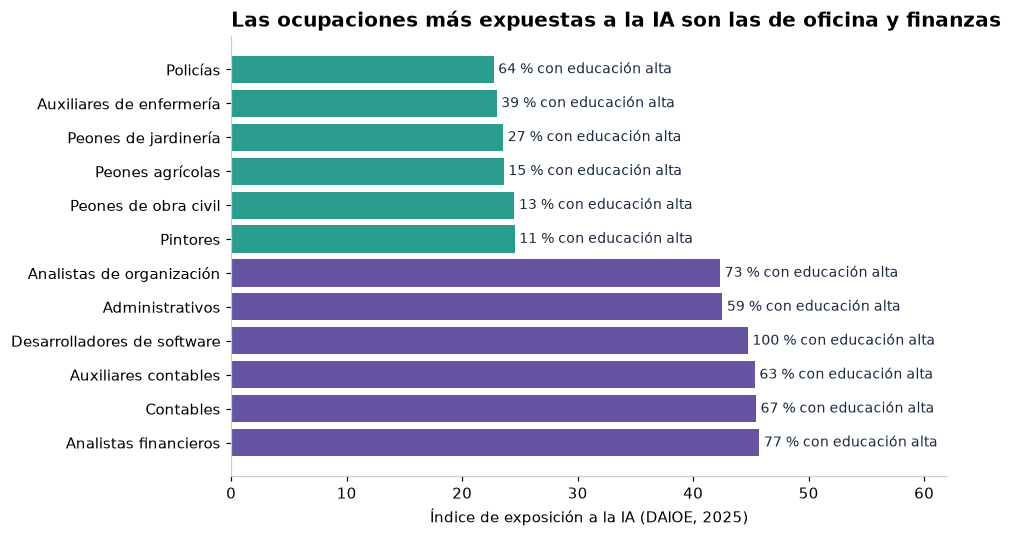

In [64]:
# PREGUNTA: ¿qué ocupaciones concretas están más (y menos) expuestas a la IA, y quién trabaja en ellas?
# PASOS: (1) unimos cada persona con el índice de su ocupación (daioe, ya cargado); (2) por ocupación calculamos cuántas
#        personas hay y qué % tiene educación alta; (3) nos quedamos con ocupaciones con al menos 15 personas (para no
#        sacar conclusiones de muy pocos casos); (4) mostramos las 6 más y las 6 menos expuestas.
w = h3[h3.paid_work == 1].copy()
w["isco"] = pd.to_numeric(w.ISCO08_C, errors="coerce")
w = w[w.isco.notna() & (w.isco != 9996)].merge(daioe[["isco", "occ_title_isco08", "daioe_allapps"]], on="isco")
prof = w.groupby(["isco", "occ_title_isco08"]).agg(personas=("education", "size"), indice_ia=("daioe_allapps", "first"),
                                                  pct_educ_alta=("education", lambda s: (s == "High").mean() * 100)).reset_index()
prof = prof[prof.personas >= 15].sort_values("indice_ia")
print("Ocupaciones con al menos 15 personas:", len(prof))
seleccion = pd.concat([prof.head(6), prof.tail(6)])
print(seleccion[["occ_title_isco08", "personas", "indice_ia", "pct_educ_alta"]].round(1).to_string(index=False))

TRAD = {"Financial analysts": "Analistas financieros", "Accountants": "Contables", "Accounting and bookkeeping clerks": "Auxiliares contables",
        "General office clerks": "Administrativos", "Management and organization analysts": "Analistas de organización",
        "Software and applications developers and analysts not elsewhere classified": "Desarrolladores de software",
        "Police officers": "Policías", "Nursing associate professionals": "Auxiliares de enfermería",
        "Garden and horticultural labourers": "Peones de jardinería", "Crop farm labourers": "Peones agrícolas",
        "Civil engineering labourers": "Peones de obra civil", "Painters and related workers": "Pintores"}
etiquetas = [TRAD.get(t, t) for t in seleccion.occ_title_isco08]
colores = [TEAL] * 6 + [PURPLE] * 6
fig, ax = plt.subplots(figsize=(8.4, 5.2))
ax.barh(range(12), seleccion.indice_ia, color=colores)
ax.set_yticks(range(12), etiquetas); ax.invert_yaxis()
for k, (idx, pct) in enumerate(zip(seleccion.indice_ia, seleccion.pct_educ_alta)):
    ax.text(idx + 0.4, k, f"{pct:.0f} % con educación alta", va="center", fontsize=9, color=NAVY)
ax.set_xlim(0, 62); ax.set_xlabel("Índice de exposición a la IA (DAIOE, 2025)"); ax.grid(axis="y", visible=False)
ax.set_title("Las ocupaciones más expuestas a la IA son las de oficina y finanzas")
plt.savefig(IMG / "h3_profesiones_ia.png", bbox_inches="tight"); plt.show()

**Resultado.** El 98,7 % de las personas con ocupación válida se pudo enlazar con DAIOE (índice de 2025). Se dividen las ocupaciones en dos grupos por la mediana del índice. En los tres niveles educativos, quienes trabajan en ocupaciones con **mayor** exposición potencial a IA tienen competencias medias más altas: +7,7 puntos (nivel bajo), +8,1 (medio) y +10,6 (alto), todas con p < 0,01 (test de Welch).

**Interpretación prudente.** Es una asociación descriptiva. El índice caracteriza ocupaciones, no mide el uso ni el impacto de la IA en una persona, y las ocupaciones más expuestas suelen ser las más cualificadas (una explicación posible que este análisis no contrasta). No se puede afirmar que la IA exija más competencias ni que las aumente.

### Veredicto H3: CONFIRMADA PARCIALMENTE

- **Por qué solo parcialmente:** la asociación es positiva pero débil (OR 1,05 por +10 puntos; V de Cramér menor de 0,09; no significativa en el nivel medio). Con pesos muestrales casi desaparece (OR 1,02). El título pesa mucho más (OR 4,4).
- **Por qué no podemos concluir más:** el resultado (`PAIDWORK5`, haber trabajado en 5 años) es burdo; título y competencias están muy relacionados (estudiar forma competencias), y la encuesta es una foto fija: no muestra cómo cambian las competencias ni el efecto de la IA.
- **Para ir más allá:** modelos con pesos y errores estándar replicados; empleo actual y salario por hora con controles (edad, experiencia, sector); otros países de PIAAC; datos longitudinales.

## 6. Mi suposición: ¿en la era de la IA importan más las competencias que el título universitario?

Respuesta corta: **en estos datos, no; pero tampoco se puede descartar para el futuro.**

- **Lo que vemos:** pasar de educación baja a alta se asocia con +21 p.p. de personas con trabajo remunerado; pasar del cuartil de competencias más bajo al más alto, con +1,5 a +8 p.p. a igual nivel de estudios.
- **Lo que no medimos:** PIAAC mide comprensión lectora y cálculo, no estudiar matemáticas o física ni habilidades con IA.
- **Lo que no podemos saber:** es una foto fija (ciclo 2, 2022-23); no se observa el futuro ni la causalidad. El título puede aportar cosas que no medimos (redes de contactos, señal ante quien contrata, acceso a puestos que lo exigen formalmente).

Es una pregunta abierta, no una hipótesis refutada.

## 7. Conclusiones

| Hipótesis | Resultado | Lo más relevante |
|---|---|---|
| H1 | Confirmada | Más educación, más empleo en los 36 países; brecha media de 31 p.p., estable en el tiempo. |
| H2 | Confirmada parcialmente | Con estudios superiores los migrantes tienen menos empleo en 34 de 34 países; con educación baja ocurre lo contrario. |
| H3 | Confirmada parcialmente | Las competencias importan, pero menos que el nivel educativo; el resultado es frágil con pesos muestrales. |

**Respuesta a la pregunta general.** En estos datos, el título formal y el origen migratorio se asocian con las perspectivas laborales más claramente que las competencias medidas por PIAAC. Las competencias aportan información adicional, pero modesta. Una idea frecuente es que en la era de la IA importan sobre todo las competencias fundamentales; estos datos no la respaldan: las competencias se asocian con el empleo, pero no sustituyen al nivel educativo. PIAAC mide literacy y numeracy, que no equivalen a estudiar matemáticas o física.

**Oportunidades (hipótesis para discutir, no resultados de los datos).** Evaluar competencias reales además de títulos en la selección de personal; acelerar el reconocimiento de títulos extranjeros; ofrecer formación corta de recualificación a migrantes con estudios superiores.

**Limitaciones.** Datos observacionales, sin causalidad. Promedios simples de países, sin ponderar por población. Los análisis de PIAAC no usan el diseño muestral complejo (solo una comprobación con pesos). `PAIDWORK5` no es el empleo actual. El índice de IA describe ocupaciones, no personas.

**Siguientes pasos.** Ver la sección 8.

## 8. Qué analizaría a continuación

1. **Microdatos de la Encuesta de Población Activa europea (EU-LFS):** comparar migrantes y no migrantes por edad, sector, años desde la llegada y país donde se estudió.
2. **Sobrecualificación:** medir cuántos migrantes con estudios superiores trabajan en puestos por debajo de su formación; es la pregunta más cercana a mi caso.
3. **PIAAC con pesos muestrales y errores estándar replicados**, con empleo actual y salario por hora, controlando edad, experiencia y sector.
4. **Más países de PIAAC:** ¿el título pesa más que las competencias también fuera de España?
5. **Exposición a IA a lo largo del tiempo:** DAIOE ofrece varios años (2022-2025) para ver si cambian las ocupaciones más expuestas.
6. **Cualitativo:** entrevistas o encuestas sobre reconocimiento de títulos, idioma y redes de contactos.